<div class="alert alert-success">
DRAFT NOTEBOOK INTENDED FOR INTERNAL USE ONLY
</div>

# Grokking - a statistical view

## Introduction
- Grokking background
- Motivation:
    - Explain grokking as a distribution shift phenomena and shed some light in ways to predict when this phenomena is likelly to happen


### Setup

The following are the import statements and basic definitions used accross the entire notebook.

In [4]:
# Basic data manipulation
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Data and visualization
import matplotlib.pyplot as plt
import matplotlib.cm as cm # colors
import seaborn as sns

# Dim analysis
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ML
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader, RandomSampler, Dataset
from transformers import Trainer, TrainingArguments

# Utils
from tqdm import tqdm
import os
from os.path import join as path_join
import json
import random
from IPython.display import display

from dataUtils import *
from trainUtils import *

In [5]:
torch.cuda.is_available()

True

In [6]:
# Check if a GPU is available and use it, otherwise use the CPU
device

device(type='cuda')


## How to run this notebook
- Cell order and obrigatory cells:

    The sections of the notebook are as much self contained as possible but also avoid running the same code twice. As a general rule of thumb, if you whant to run the cells of an specific section, run all cells in the "Setup" subsections of the previous sections. This will garantee you have all data structures needed and also avoid run unecessary code.
    Also, ensure that cuda is available if you want to run the MLP and Transformer Models. The setup of the introduction section will show if you have cuda available.
    
- The pdf/html version of this notebook does not include many auxiliary cells (including the "Setup" sections).

    We made this decision to have concise files that reader con focus on the data, method and analysis itself instead of bothering will all the finer details of the experimental setup.



## Background
When have grokking been spotted
Different models and explanations of grokking

### Setup

In [7]:
# Load the dataset into a Pandas DataFrame
df_doubleit = pd.read_csv("datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13.csv")

# Display basic summary statistics
print(df_doubleit.dtypes)
df_doubleit["class"] = df_doubleit["class"].astype("category")
df_doubleit["super_class"] = df_doubleit["super_class"].astype("category")

summary_stats = df_doubleit.describe()
summary_stats

class            int64
super_class      int64
d0             float64
d1             float64
d2             float64
                ...   
d112           float64
d113           float64
d114           float64
d115           float64
d116           float64
Length: 119, dtype: object


,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,...,d107,d108,d109,d110,d111,d112,d113,d114,d115,d116
count,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,...,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000,400000.000000
mean,0.824656,-0.917012,-0.648337,-0.503982,-0.500555,-0.940863,0.059603,-0.787484,-0.195140,-0.077333,...,-0.881360,-0.697917,-1.167072,0.059715,-0.520217,0.452182,0.129376,0.421614,-0.317911,-0.694002
std,0.163690,0.200898,0.191362,0.145087,0.130832,0.144547,0.211682,0.172355,0.246249,0.209926,...,0.154756,0.167240,0.224404,0.197861,0.189889,0.154350,0.160577,0.169677,0.211781,0.225393
min,0.177189,-1.626799,-1.313391,-1.146207,-1.144278,-1.592935,-0.756744,-1.485887,-0.935264,-0.820708,...,-1.479762,-1.351902,-1.960858,-0.626297,-1.175290,-0.177159,-0.585922,-0.278030,-0.991346,-1.435224
25%,0.707078,-1.071290,-0.802270,-0.602147,-0.588804,-1.038834,-0.109079,-0.913324,-0.410099,-0.255675,...,-0.991181,-0.824199,-1.357239,-0.100689,-0.673642,0.338937,0.011585,0.300023,-0.494335,-0.880871
50%,0.824702,-0.917360,-0.648118,-0.504036,-0.500367,-0.940648,0.059248,-0.787569,-0.195361,-0.077102,...,-0.881146,-0.698049,-1.166393,0.058896,-0.520139,0.452057,0.129424,0.421545,-0.317631,-0.693776
75%,0.942013,-0.762883,-0.494671,-0.405679,-0.411979,-0.842807,0.228115,-0.661830,0.019965,0.100849,...,-0.771212,-0.571439,-0.977312,0.220587,-0.366678,0.565439,0.246896,0.542885,-0.141807,-0.507399
max,1.536039,-0.189330,0.023923,0.171375,0.079873,-0.274345,0.777354,-0.025255,0.623728,0.559083,...,-0.194253,-0.054882,-0.433648,0.707224,0.160150,1.078662,0.793516,1.140387,0.420834,0.063622


In [8]:
doubleit_class_map = {}

# Iterate through unique 'super_class' values
for super_class in df_doubleit['super_class'].unique():
    # Filter the DataFrame for rows with the current 'super_class'
    filtered_df = df_doubleit[df_doubleit['super_class'] == super_class]
    
    # Get the list of 'class' values that appear with the current 'super_class'
    class_values = filtered_df['class'].unique().tolist()
    
    # Add the mapping to the dictionary
    doubleit_class_map[super_class] = class_values
    
pd.DataFrame(doubleit_class_map)

,63,240,323,396
0,31,112,67,140
1,47,176,259,268
2,55,208,321,388
3,59,224,322,392
4,61,240,323,396
5,62,241,327,397
6,63,242,331,398
7,127,244,339,412
8,191,248,355,428
9,319,496,451,460


In [9]:
sample_classes(doubleit_class_map, .1, random_seed = 42)

[47, 112, 323, 392]

In [10]:
# If there the training split is already saved into a csv file, then load it
if os.path.isfile('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_train.csv'):
    train_df_doubleit = pd.read_csv('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_train.csv')
    test_df_doubleit = pd.read_csv('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_test.csv')

In [11]:
# If there is no training and test split saved: split the dataset into training and test
if not os.path.isfile('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_train.csv'):
    test_size = 0.4
    X = df_doubleit.drop(["class", "super_class"], axis=1)  # Features (numeric columns)
    y = df_doubleit[["class", "super_class"]]  # Target variables

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y)
    # Create DataFrames for training and test data
    train_df_doubleit = pd.concat([X_train, y_train], axis=1)
    test_df_doubleit = pd.concat([X_test, y_test], axis=1)

In [12]:
# If there is no training and test split saved: save the DataFrames to CSV files
if not os.path.isfile('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_train.csv'):
    train_df_doubleit.to_csv('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_train.csv', index=False)
    test_df_doubleit.to_csv('datasets/V0_binaryTreeMultiDim_distSuperClasses_ns_10000_ndg_9_ndpg_13_test.csv', index=False)

In [13]:
train_df_doubleit.describe()

,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,...,d109,d110,d111,d112,d113,d114,d115,d116,class,super_class
count,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,...,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000
mean,0.824802,-0.916740,-0.648409,-0.504217,-0.500888,-0.941210,0.059585,-0.787638,-0.194950,-0.077323,...,-1.167247,0.060083,-0.520092,0.452113,0.129430,0.421857,-0.317864,-0.693926,255.500000,255.500000
std,0.163418,0.201109,0.191295,0.145240,0.130878,0.144548,0.211668,0.172522,0.246381,0.210077,...,0.224464,0.197747,0.190016,0.154530,0.160516,0.169719,0.211881,0.225329,134.078801,124.089944
min,0.177189,-1.626799,-1.313391,-1.126787,-1.078183,-1.592935,-0.756744,-1.457946,-0.912184,-0.712700,...,-1.843386,-0.615326,-1.175290,-0.177159,-0.506296,-0.255276,-0.983567,-1.435224,31.000000,63.000000
25%,0.707439,-1.071128,-0.802330,-0.602345,-0.588832,-1.039265,-0.108908,-0.913542,-0.409890,-0.255661,...,-1.357443,-0.100137,-0.673633,0.338572,0.011965,0.300262,-0.494852,-0.880824,136.750000,195.750000
50%,0.824673,-0.916783,-0.648038,-0.504151,-0.500485,-0.941100,0.059246,-0.787761,-0.195622,-0.077088,...,-1.166747,0.059320,-0.520350,0.451964,0.129316,0.421828,-0.317772,-0.693462,253.500000,281.500000
75%,0.942049,-0.762375,-0.495140,-0.406314,-0.412310,-0.843136,0.227869,-0.661952,0.020259,0.101040,...,-0.977456,0.221010,-0.366372,0.565347,0.246939,0.542955,-0.141682,-0.507816,363.250000,341.250000
max,1.515021,-0.190036,0.023923,0.171375,0.079873,-0.274345,0.762089,-0.025255,0.623728,0.559083,...,-0.445263,0.707224,0.160150,1.078662,0.793516,1.140387,0.391745,0.062075,496.000000,396.000000


In [14]:
test_df_doubleit

,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,...,d109,d110,d111,d112,d113,d114,d115,d116,class,super_class
0,0.886101,-1.037953,-0.794117,-0.503033,-0.698349,-1.160612,0.185236,-0.807150,0.256458,0.165009,...,-1.444867,-0.251028,-0.757692,0.672888,0.376244,0.319850,-0.399750,-0.603360,323,323
1,0.929553,-1.092571,-0.648193,-0.574758,-0.544528,-0.925466,0.087594,-0.817758,-0.067030,0.359404,...,-1.133614,0.174941,-0.388786,0.524306,-0.091619,0.722868,-0.072706,-1.037743,241,240
2,0.994824,-1.066498,-0.921428,-0.481817,-0.518926,-1.234646,0.165352,-0.489492,-0.115669,0.216853,...,-1.089284,-0.158688,-0.742803,0.424536,0.313785,0.135117,-0.459770,-0.514839,339,323
3,0.701517,-0.871590,-0.422670,-0.540228,-0.397971,-0.842271,-0.240633,-1.022537,-0.396449,-0.325590,...,-1.211356,0.142925,-0.424362,0.070588,0.119145,0.298916,0.003721,-1.031586,208,240
4,0.703129,-0.833239,-0.456816,-0.587708,-0.317130,-0.918410,-0.194196,-0.842784,-0.270756,-0.235106,...,-1.053559,0.373176,-0.503250,0.366017,-0.150409,0.442903,-0.051241,-1.047983,176,240
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159995,0.918623,-0.996456,-0.743277,-0.482361,-0.739663,-1.080549,0.109962,-0.766078,-0.153579,0.129566,...,-0.995022,0.255756,-0.276697,0.384145,-0.075792,0.350998,-0.251359,-0.877748,47,63
159996,0.684189,-0.892492,-0.885803,-0.339215,-0.809743,-1.212744,0.325532,-0.780409,0.259127,0.188152,...,-1.414210,-0.036385,-0.630610,0.544021,0.160156,0.501849,-0.757558,-0.588413,327,323
159997,0.744079,-0.683597,-0.624030,-0.642858,-0.462528,-0.665217,-0.254857,-0.912811,-0.416495,-0.079936,...,-0.735063,0.291141,-0.422889,0.065107,0.009156,0.625041,-0.124408,-0.845728,176,240
159998,0.839290,-0.791745,-0.516773,-0.453983,-0.512226,-0.940137,-0.274265,-0.951710,-0.188852,-0.309501,...,-1.139879,0.011301,-0.612486,0.554415,0.277881,0.389524,-0.377002,-0.522770,460,396


In [16]:
train_doubleit = DoubleItDataset(train_df_doubleit)
test_doubleit = DoubleItDataset(test_df_doubleit)

### Dataset Analysis

#### Data distribution

In [17]:
print(df_doubleit.dtypes)
print(f"\nThere are {df_doubleit['class'].unique().size} classes. Split into {df_doubleit['super_class'].unique().size} super-classes:\n")

# Group by "super_class" and count the unique values of "class" for each group
class_count_by_super_class = df_doubleit.groupby('super_class')['class'].nunique().reset_index()

# Rename the columns for clarity
class_count_by_super_class.columns = ['super_class', 'class_count']

# Display the result
print(class_count_by_super_class)

class          category
super_class    category
d0              float64
d1              float64
d2              float64
                 ...   
d112            float64
d113            float64
d114            float64
d115            float64
d116            float64
Length: 119, dtype: object

There are 40 classes. Split into 4 super-classes:

  super_class  class_count
0          63           10
1         240           10
2         323           10
3         396           10


<ipython-input-17-0d61375e694c>:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  class_count_by_super_class = df_doubleit.groupby('super_class')['class'].nunique().reset_index()


In [18]:
train_df_doubleit['super_class'].unique()

array([323,  63, 396, 240])

In [19]:
f,t = train_doubleit[0]
print(f"Features shape = {f.shape}")

Features shape = torch.Size([117])


Remove empty subplots: 100%|██████████| 4/4 [00:00<00:00, 37786.52it/s]


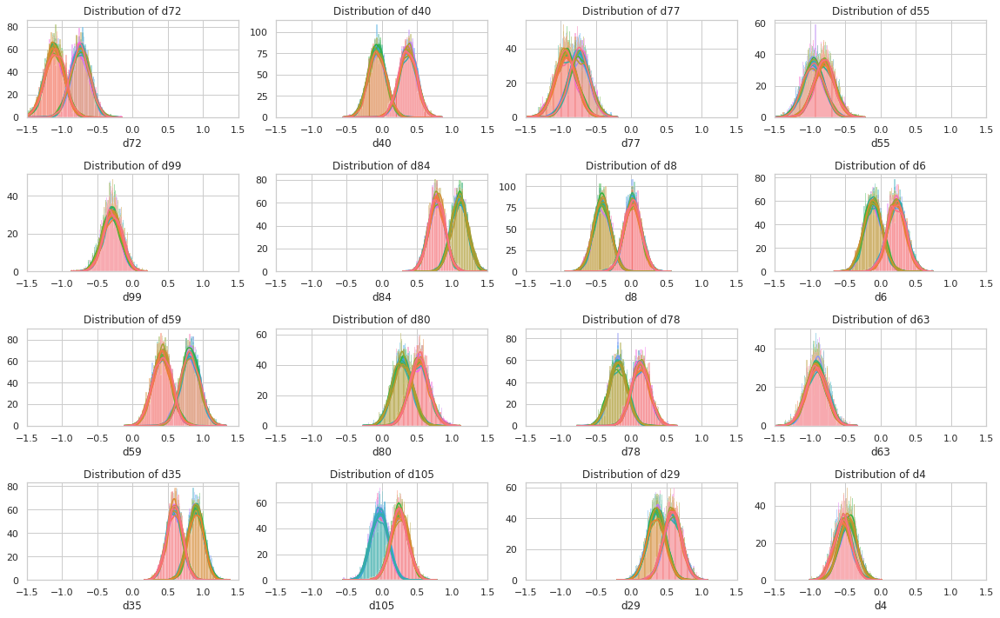

In [21]:
# Define the number of columns to be displayed in each row of subplots
cols_per_row = 4 

num_dims = 116
num_dims_to_plot = 16  # number of numerical columns to be ploted ( between d0 to d116)
assert num_dims_to_plot <= num_dims, "More columns than dimensions"

plot_dist_grid(df_doubleit,num_dims, num_dims_to_plot, cols_per_row, "class", x_min=-1.5, x_max=1.5, fraction = 0.1)

Remove empty subplots: 100%|██████████| 5/5 [00:00<00:00, 43965.45it/s]


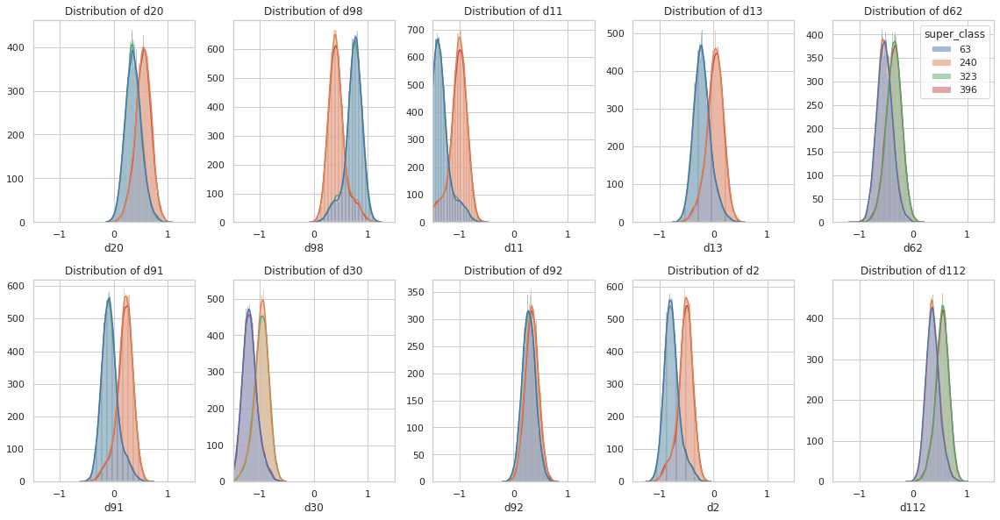

In [25]:
plot_dist_grid(df_doubleit,num_dims, num_cols, cols_per_row, "super_class", x_min=-1.5, x_max=1.5, fraction = 0.1)

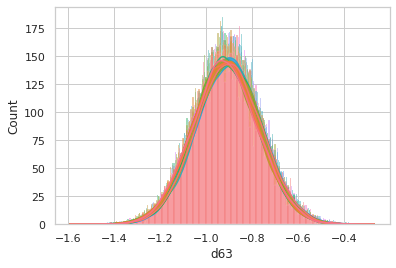

In [22]:
col="d63"
sns.histplot(data=df_doubleit, x=col, hue='class', kde=True, common_norm=False, legend=False)
plt.show()

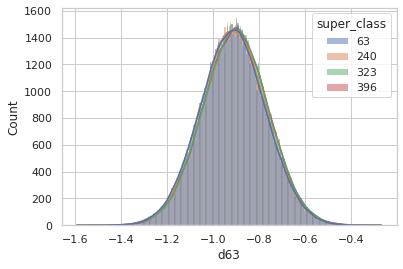

In [27]:
col="d63"
sns.histplot(data=df_doubleit, x=col, hue='super_class', kde=True, common_norm=False)
plt.show()

Remove empty subplots: 100%|██████████| 1/1 [00:00<00:00, 10255.02it/s]


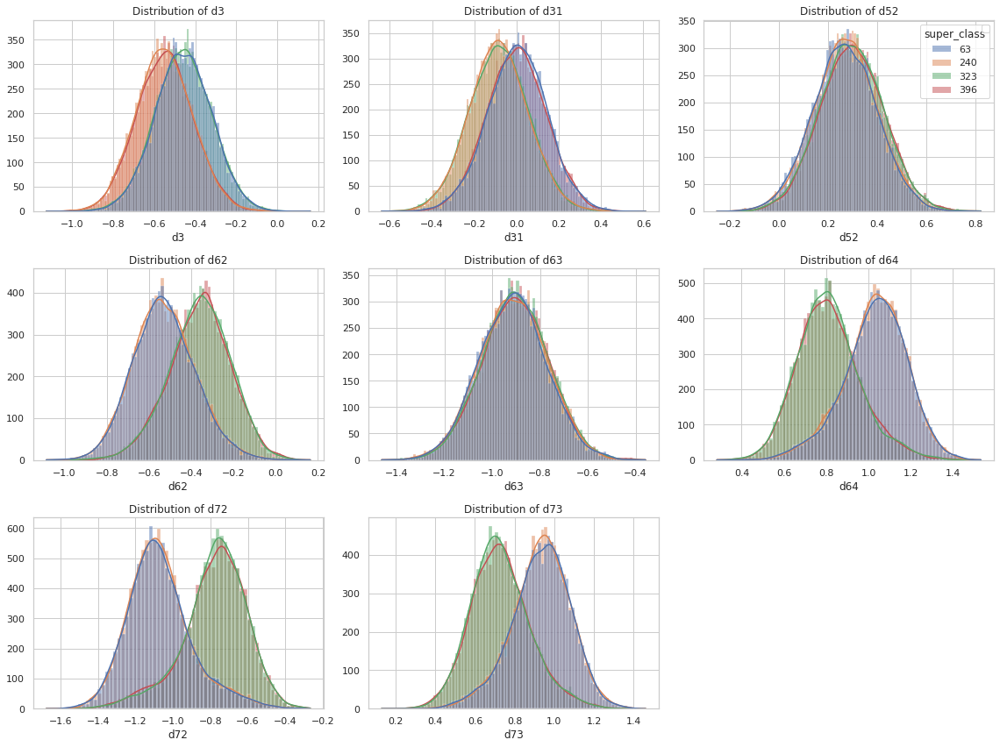

In [28]:
plot_dist_grid_list(df_doubleit,[3, 31, 52, 62, 63, 64, 72, 73], cols_per_row=3, class_col="super_class", fraction = 0.1)

Remove empty subplots: 100%|██████████| 3/3 [00:00<00:00, 15363.75it/s]


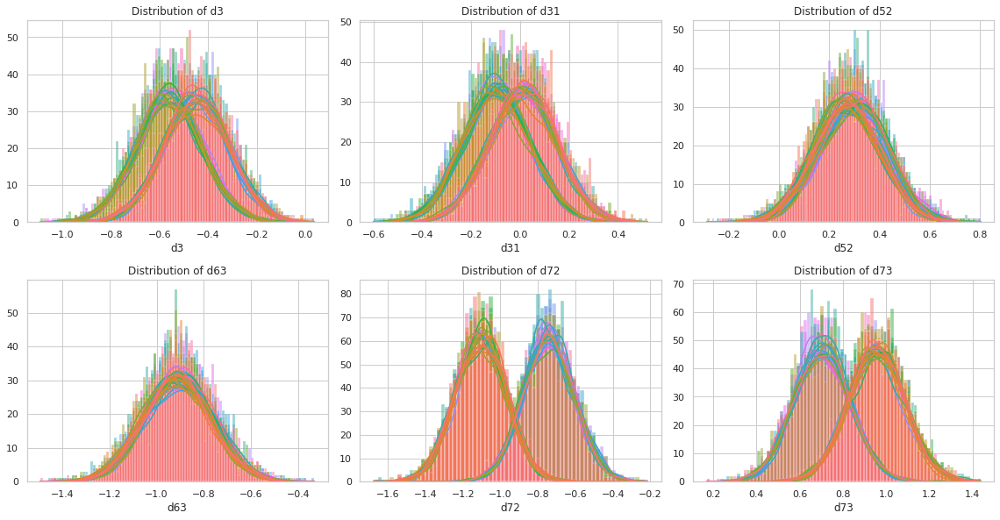

In [23]:
plot_dist_grid_list(df_doubleit,[3, 31, 52, 63, 72, 73], cols_per_row=3, class_col="class", fraction = 0.1)

In [30]:
# Count how many samples per class
class_counts = df_doubleit['class'].value_counts()

# Check if all counts are equal
print(f"All counts are equal to {class_counts.iloc[0]}" if (class_counts == class_counts.iloc[0]).all() else "The counts differ!")

All counts are equal to 10000


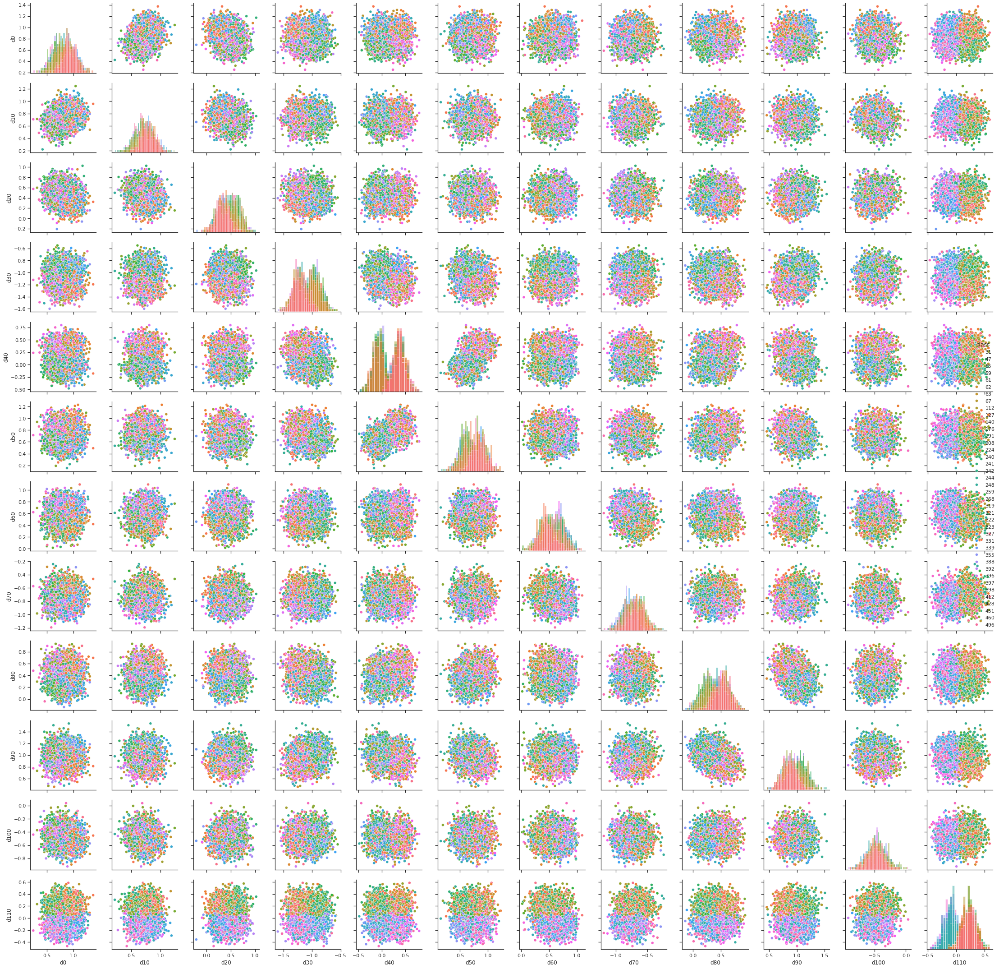

In [32]:
pairplot(dim_cols=range(0, 117, 10), class_col="class", fraction=0.01)

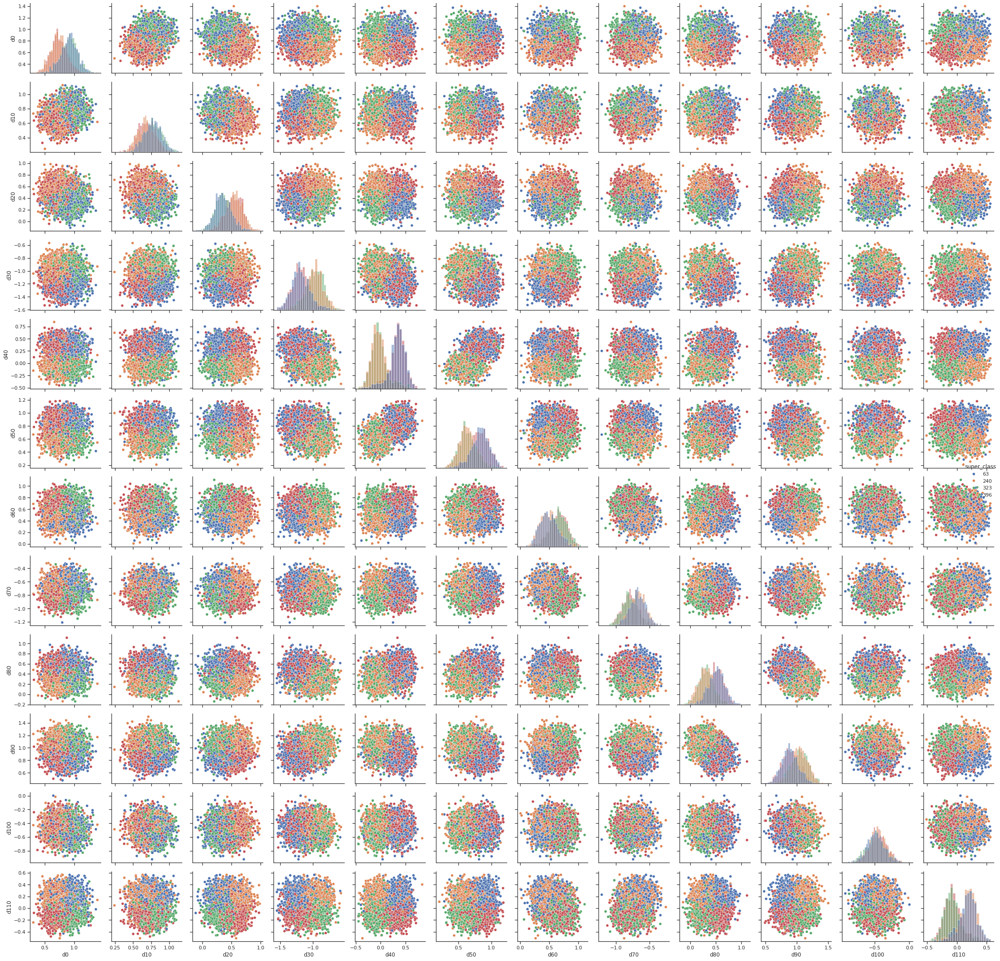

In [33]:
pairplot(dim_cols=range(0, 117, 10), class_col="super_class", fraction=0.01)

#### Checking data properties
    - each subclass is a multi-variate distribution
    - each subclass mean is equidistant from every other subclass mean
    - all classes centroids are equidistant from every other class centroid

#### Dimension reduction analysis

In [15]:
# Extract the features (d1 to d116)
features = df_doubleit.iloc[:, 2:]

# Standardize the features
features_standardized = (features - features.mean()) / features.std()

features_standardized

,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,...,d107,d108,d109,d110,d111,d112,d113,d114,d115,d116
0,0.944106,-1.103210,-1.249751,0.641081,-1.234977,-0.875060,1.493235,0.718204,0.605999,0.531655,...,0.278235,-1.564321,0.153902,1.404624,1.291507,-0.524665,-0.717353,0.572668,0.253997,-1.730504
1,0.306957,-0.021233,-0.312949,-0.924240,-0.693928,-0.698007,0.801702,1.938129,0.857198,0.697853,...,-0.497470,-0.634865,1.518824,1.366917,2.560573,-0.799335,-0.281374,-0.607375,0.567514,-1.334884
2,0.342229,-1.168386,-0.614558,0.117842,0.471171,-0.016658,1.206171,0.652419,1.060656,0.410598,...,-0.132714,-0.950108,1.628923,1.807568,0.828535,-0.906911,-0.424245,-0.084824,-0.933590,-1.430479
3,-1.100198,-0.224094,-1.640086,0.290797,-0.770798,-0.059067,0.624790,0.585232,0.511844,0.098899,...,-0.818719,-0.246952,1.217725,0.502682,0.849378,-0.536896,0.065389,0.886277,1.032569,0.010460
4,1.409146,-1.076504,-0.767626,0.282607,-0.268081,-0.854071,1.311788,-0.450134,0.657194,1.119462,...,-0.066232,-0.279386,0.570822,0.228868,-0.847696,-0.291861,-0.874270,1.235635,0.943651,-0.444497
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,-0.446613,1.101677,0.923120,-0.649531,-0.276350,0.787924,-0.546162,0.333561,-1.488941,-1.644924,...,0.028973,1.930577,0.118896,-0.633649,-2.140041,1.166659,0.550705,-0.797073,-1.079111,0.416897
399996,-0.909869,0.642956,-0.261907,-0.260799,1.073524,1.089114,0.005089,-0.980441,-0.631143,-0.815629,...,1.209662,0.262609,-0.688255,-1.969887,-0.013292,0.865040,2.286320,-1.460235,-0.311096,-0.996254
399997,-1.157092,0.444439,-0.379821,-0.623034,0.467210,-0.447462,-0.262440,-1.242953,-0.678895,-1.295054,...,1.338276,0.205523,-0.344000,-1.301959,0.465383,0.585561,1.353152,-1.493877,-1.374309,0.719707
399998,0.420110,0.764104,1.472327,-2.077075,0.914458,-0.549589,-0.767148,0.902709,-0.541972,-0.981549,...,-0.642777,1.154757,-1.376266,-0.818586,-0.560922,1.193962,1.516428,0.068891,-1.375722,0.710963


In [16]:
# PCA for two dimensions
pca = PCA(n_components=2)
pca_result_2d = pca.fit_transform(features_standardized)

# PCA for three dimensions
pca = PCA(n_components=3)
pca_result_3d = pca.fit_transform(features_standardized)

pca_df_2d = pd.DataFrame(data=pca_result_2d, columns=['PC1', 'PC2'])
pca_df_2d = pd.concat([df_doubleit[['class', 'super_class']], pca_df_2d], axis=1)

pca_df_3d = pd.DataFrame(data=pca_result_3d, columns=['PC1', 'PC2', 'PC3'])
pca_df_3d = pd.concat([df_doubleit[['class', 'super_class']], pca_df_3d], axis=1)

,class,super_class,PC1,PC2
0,31,63,-4.798874,-0.792919
1,31,63,-4.129753,-1.567798
2,31,63,-3.678784,-1.961356
3,31,63,-4.519305,-2.162449
4,31,63,-5.575256,-0.440865
...,...,...,...,...
399995,460,396,-0.059104,3.974614
399996,460,396,-0.485452,4.413297
399997,460,396,-0.763349,4.150644
399998,460,396,-1.307180,4.657786


/dccstor/kcsys/brenow/.conda/envs/torch_cuda_1.12/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


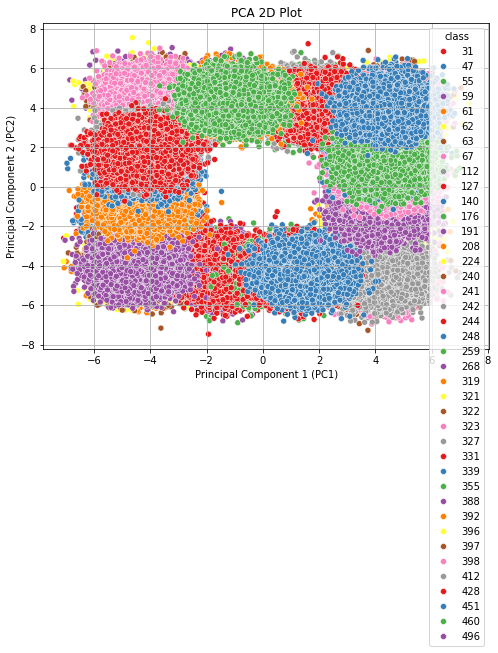

In [31]:
display(pca_df_2d)
# Create a 2D scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue="class", data=pca_df_2d, palette='Set1')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA 2D Plot')
plt.grid()
plt.show()

,class,super_class,PC1,PC2,PC3
0,31,63,-4.798874,-0.792919,-4.738895
1,31,63,-4.129753,-1.567798,-4.840082
2,31,63,-3.678784,-1.961356,-4.877900
3,31,63,-4.519305,-2.162449,-3.988762
4,31,63,-5.575256,-0.440865,-4.447516
...,...,...,...,...,...
399995,460,396,-0.059104,3.974614,4.038306
399996,460,396,-0.485452,4.413297,4.504116
399997,460,396,-0.763349,4.150644,3.696867
399998,460,396,-1.307180,4.657786,3.320349


<ipython-input-42-6556a44d56ad>:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("tab20", len(classes.unique()))


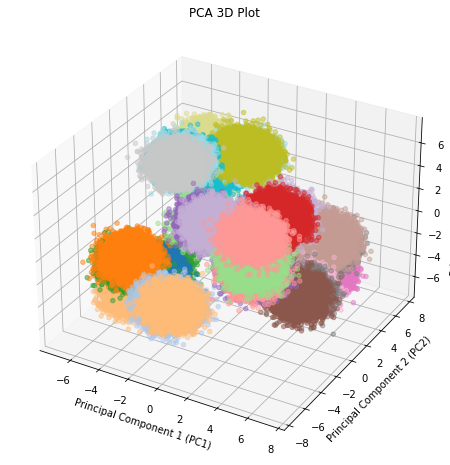

In [42]:
display(pca_df_3d)

# Create a 3D scatter plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

classes = pca_df_3d['class']
colors = cm.rainbow(np.linspace(0, 1, len(classes.unique())))

for cl, co in zip(classes.unique(), colors):
    idx = (classes == cl)
    ax.scatter(pca_df_3d.loc[idx, 'PC1'], pca_df_3d.loc[idx, 'PC2'], pca_df_3d.loc[idx, 'PC3'], color= co, alpha=0.5)
ax.set_xlabel('Principal Component 1 (PC1)')
ax.set_ylabel('Principal Component 2 (PC2)')
ax.set_zlabel('Principal Component 3 (PC3)')
ax.set_title('PCA 3D Plot')
plt.show()

In [17]:
# PCA for three dimensions
n_dims = 9
pca = PCA(n_components=n_dims)
pca_result_9d = pca.fit_transform(features_standardized)

pca_df_9d = pd.DataFrame(data=pca_result_9d, columns=[f'PC{i}'for i in range(1,n_dims+1)])
pca_df_9d = pd.concat([df_doubleit[['class', 'super_class']], pca_df_9d], axis=1)


Explained Variance Ratio: [0.11927902 0.11820513 0.11048559 0.02587253 0.02571812 0.02455953
 0.02405385 0.02297814 0.02176115]
Cumulative Explained Variance: [0.11927902 0.23748415 0.34796974 0.37384227 0.39956039 0.42411991
 0.44817376 0.4711519  0.49291305]
Eigenvalues: [13.95564484 13.83000057 12.92681405  3.02708572  3.00901994  2.87346444
  2.81430041  2.68844273  2.54605434]


,class,super_class,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
0,31,63,-4.798874,-0.792919,-4.738895,-3.081541,-0.730361,0.112003,0.021444,3.676550,-0.285549
1,31,63,-4.129753,-1.567798,-4.840082,-3.666655,-1.182096,0.642719,-0.147426,3.678745,-0.958776
2,31,63,-3.678784,-1.961356,-4.877900,-2.122676,0.162330,-0.315280,-0.179043,2.673450,-0.577790
3,31,63,-4.519305,-2.162449,-3.988761,-1.787261,-1.041202,-1.627016,-0.079036,3.828814,-0.408558
4,31,63,-5.575256,-0.440865,-4.447516,-2.029223,-0.617314,-0.130336,-0.373676,2.796362,-0.123720
...,...,...,...,...,...,...,...,...,...,...,...
399995,460,396,-0.059104,3.974614,4.038306,1.093636,4.342336,-0.270848,2.551720,-0.033585,0.014435
399996,460,396,-0.485452,4.413297,4.504116,-0.522271,3.471651,0.967239,0.495194,0.056007,-0.138468
399997,460,396,-0.763349,4.150644,3.696867,-0.373953,3.097302,0.407915,0.429047,1.242985,0.009426
399998,460,396,-1.307180,4.657786,3.320349,-1.351781,4.399609,-0.596558,0.636444,-0.107901,0.713188


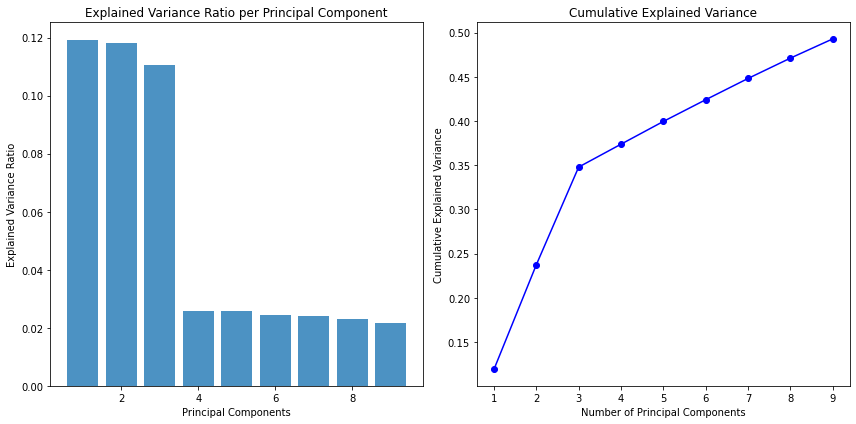

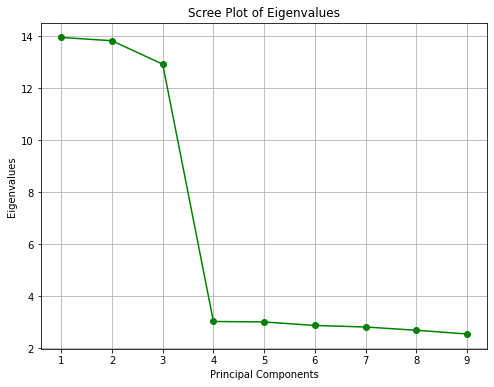

In [18]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance_ratio)
eigenvalues = pca.explained_variance_

print(f"Explained Variance Ratio: {explained_variance_ratio}")
print(f"Cumulative Explained Variance: {cumulative_explained_variance}")
print(f"Eigenvalues: {eigenvalues}")
display(pca_df_9d)

# Scree Plot
plt.figure(figsize=(12, 6))

# Explained Variance Ratio Plot
plt.subplot(1, 2, 1)
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, align='center', alpha=0.8)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance Ratio per Principal Component')

# Cumulative Explained Variance Plot
plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')

plt.tight_layout()
plt.show()

# Scree Plot for Eigenvalues
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='-', color='g')
plt.xlabel('Principal Components')
plt.ylabel('Eigenvalues')
plt.title('Scree Plot of Eigenvalues')
plt.grid()
plt.show()

[0]31: Explained Variance Ratio: [0.01343892 0.01317212 0.01299583 0.01274496 0.01252521 0.01226081
 0.01212514 0.01194399 0.01192201]
[0]31: Cumulative Explained Variance: [0.01343892 0.02661104 0.03960687 0.05235184 0.06487705 0.07713786
 0.089263   0.10120699 0.113129  ]
[0]31: Eigenvalues: [1.55891463 1.52796617 1.50751637 1.47841588 1.45292452 1.4222543
 1.40651576 1.38550299 1.38295297]

[1]47: Explained Variance Ratio: [0.01391837 0.0130409  0.01273508 0.01264648 0.01242179 0.01228176
 0.01214709 0.01201729 0.01198205]
[1]47: Cumulative Explained Variance: [0.01391837 0.02695927 0.03969434 0.05234082 0.06476261 0.07704436
 0.08919145 0.10120874 0.11319079]
[1]47: Eigenvalues: [1.61453039 1.51274442 1.47726887 1.4669912  1.44092772 1.42468373
 1.40906214 1.39400524 1.38991784]

[2]55: Explained Variance Ratio: [0.01375626 0.01310532 0.01275683 0.01271723 0.01259273 0.01250684
 0.01236912 0.01208454 0.01186717]
[2]55: Cumulative Explained Variance: [0.01375626 0.02686158 0.0396184

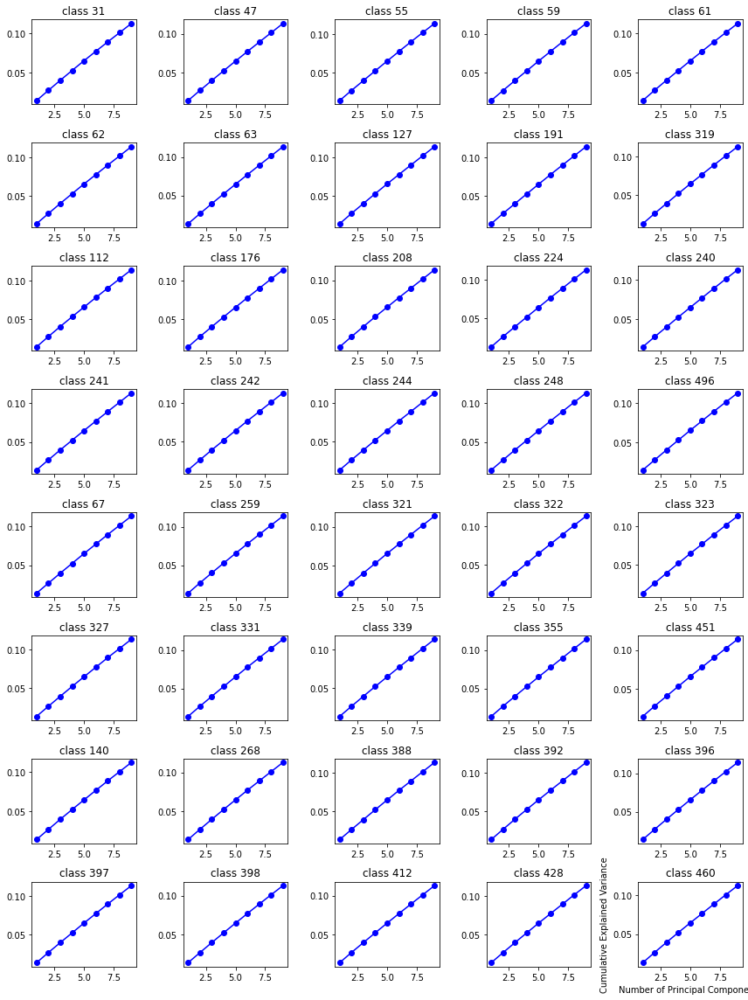

In [61]:
# Extract the features (d1 to d116)
classes = df_doubleit["class"]
n_classes = len(classes.unique())
n_cols = 5
n_rows = n_classes//n_cols + (1 if n_classes % n_cols else 0)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 16))

for count, cl in enumerate(classes.unique()):
    features_by_class = df_doubleit.loc[classes == cl, [f"d{i}" for i in range(1, 116+1)]]
    # Standardize the features
    features_by_class_standardized = (features_by_class - features_by_class.mean()) / features_by_class.std()

    n_dims = 9
    pca = PCA(n_components=n_dims)
    pca_result_9d = pca.fit_transform(features_by_class_standardized)

    pca_df_9d = pd.DataFrame(data=pca_result_9d, columns=[f'PC{i}'for i in range(1,n_dims+1)])
    pca_df_9d = pd.concat([df_doubleit[['class', 'super_class']], pca_df_9d], axis=1)

    explained_variance_ratio = pca.explained_variance_ratio_
    cumulative_explained_variance = np.cumsum(explained_variance_ratio)
    eigenvalues = pca.explained_variance_
    
    print(f"[{count}]{cl}: Explained Variance Ratio: {explained_variance_ratio}")
    print(f"[{count}]{cl}: Cumulative Explained Variance: {cumulative_explained_variance}")
    print(f"[{count}]{cl}: Eigenvalues: {eigenvalues}")
    print()

    # Cumulative Explained Variance Plot
    ax = axes[(count//n_cols), (count%n_cols)]
    ax.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='-', color='b')
    #vax.set_ylabel('Cumulative Explained Variance')
    ax.set_title(f'class {cl}')
plt.ylabel('Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.tight_layout()
plt.show()

In [34]:
# t-SNE for two dimensions
tsne = TSNE(n_components=2, random_state=42)
tsne_result_2d = tsne.fit_transform(features_standardized)

# t-SNE for three dimensions
tsne = TSNE(n_components=3, random_state=42)
tsne_result_3d = tsne.fit_transform(features_standardized)

tsne_df_2d = pd.DataFrame(data=tsne_result_2d, columns=['TSNE1', 'TSNE2'])
tsne_df_3d = pd.DataFrame(data=tsne_result_3d, columns=['TSNE1', 'TSNE2', 'TSNE3'])


KeyboardInterrupt: 

In [ ]:
# Concatenate the results with the original DataFrame
tsne_df_2d = pd.concat([df_doubleit[['class', 'super_class']], tsne_df_2d], axis=1)
tsne_df_3d = pd.concat([df_doubleit[['class', 'super_class']], tsne_df_3d], axis=1)

NameError: name 'df_2d' is not defined

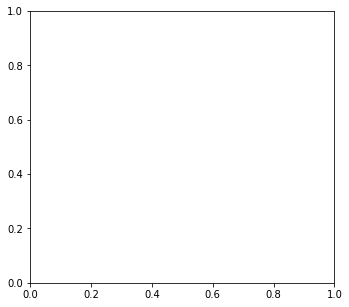

In [ ]:
# Visualize the results (scatter plots)
plt.figure(figsize=(12, 5))

# 2D PCA and t-SNE
sns.scatterplot(data=tsne_df_2d, x='TSNE1', y='TSNE2', hue='class')
plt.title('t-SNE analysis')
plt.show()

In [ ]:
# 3D PCA and t-SNE
ax = plt.subplot(1, 2, 2, projection='3d')
scatter = ax.scatter(tsne_df_3d['TSNE1'], tsne_df_3d['TSNE2'], tsne_df_3d['TSNE3'], c=tsne_df_3d['class'], cmap='viridis')
ax.set_xlabel('TSNE1')
ax.set_ylabel('TSNE2')
ax.set_zlabel('TSNE3')
plt.title('t-SNE (3D)')
plt.legend(handles=scatter.legend_elements()[0], labels=df_doubleit['class'].unique())

plt.tight_layout()
plt.show()

## Experiments

- Dataset Split
- Architectures
    We use the arquitectures XPTO, following the literature on [CITATIONS]. This way, we were able to reproduce the Grokking phenomena in our synthetic dataset. Thus we have empirical suport for our hypothesis that grokking is actually a distribution shift phenomena, where the distortion caused by regularization allows the model to move the decision boundary in a meaningful way even though there is near-zero loss incentive.
    We also use decision forrests.
- Goal: Show the relationship between a specific kind of data distribution shift and the occurrence of grokking. Grokking occurence depends on the dataset, model, and learning parameters, we aim to inspect some of those relationships.
    


### Dataset and Data Split



#### Setup

In [21]:
# Load MNIST dataset
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
full_mnist_train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_mnist_dataset = datasets.MNIST(root='./data', train=False, transform=transform)


From the Literature

- MNIST: we use the same splits as [Omnigrok](https://arxiv.org/abs/2210.01117) the minist dataset has 60,000 training images and 10,000 testing images.
- NIST: The not mixed MNIST. MNIST was created by "re-mixing" the samples from NIST's original datasets. The creators felt that since NIST's training dataset was taken from American Census Bureau employees, while the testing dataset was taken from American high school students, it was not well-suited for machine learning experiments[Wiki](https://en.wikipedia.org/wiki/MNIST_database). In our case it presents a possible distribution shift that might induce grokking. [7] Furthermore, the black and white images from NIST were normalized to fit into a 28x28 pixel bounding box and anti-aliased, which introduced grayscale levels [Wiki](https://en.wikipedia.org/wiki/MNIST_database).


### Architectures
We use the arquitectures XPTO, following the literature on [CITATIONS]. This way, we were able to reproduce the Grokking phenomena in our synthetic dataset. Thus we have empirical suport for our hypothesis that grokking is actually a distribution shift phenomena, where the distortion caused by regularization allows the model to move the decision boundary in a meaningful way even though there is near-zero loss incentive.
We also use decision forrests.


#### Setup

- **ReLU MLP**

In [22]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_hidden_layers):
        super(MLP, self).__init__()
        self.name= f"MLP_{hidden_size}_{output_size}_{num_hidden_layers}"
        
        # Input layer
        self.layers = nn.ModuleList([nn.Linear(input_size, hidden_size)])
        
        # Hidden layers
        for _ in range(num_hidden_layers - 1):
            self.layers.append(nn.Linear(hidden_size, hidden_size))
            
        # Output layer
        self.out_layer = nn.Linear(hidden_size, output_size)
        
        # ReLU activation function
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for layer in self.layers:
            x = self.relu(layer(x))
        x = self.out_layer(x)
        return x

- **2-Layer Transformer**

    Decoder-only transformer with causal attention masking  with 2 layers, width 128, and 4 attention heads. Optimized with Adam, using different $\alpha$ and $\gamma$ values.

In [23]:
class DecoderTransformer(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, num_heads):
        super(DecoderTransformer, self).__init__()
        self.name = f"DecoderTransformer_{input_dim}_{hidden_dim}_{num_layers}_{num_heads}"

        # Define the layers, including causal attention masking
        self.layers = nn.ModuleList([
            nn.TransformerDecoderLayer(
                d_model=hidden_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim * 2,
                dropout=0.1
            )
            for _ in range(num_layers)
        ])
        self.transformer = nn.TransformerDecoder(self.layers, num_layers)

        # Output layer
        self.fc = nn.Linear(hidden_dim, 10)  # 10 classes for MNIST

    def forward(self, x):
        x = self.transformer(x)
        x = self.fc(x)
        return x

model = DecoderTransformer(input_dim=28*28, hidden_dim=128, num_layers=2, num_heads=4)


### Experiments from the literature - MNIST

- Define different $\alpha$ (learning rate) and $\gamma$ (weight decay) values to be examined.
- Define different dataset fractions t be used


#### Benchmark: Decision Forrest
We use a decision forrest to also analyse the separability of the dataset (might not be included in the final paper)

In [27]:
len(full_mnist_train_dataset)

60000

In [39]:
# Define the data fractions
data_fracs = [0.25, 0.35, 0.4 , 0.45, 0.5 , 0.55,
             0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 ,
             0.95, 1.
             ]
num_runs = 10
print(f"MNIST data fractions: {str(list(data_fracs))[1:-1]}")

# Initialize lists to store accuracies
accuracies = []

print(f"Original train dataset size {full_mnist_train_dataset.data.size()}")

# Loop over each fraction
for fraction in data_fracs:
    fraction_accuracies = []
    num_samples = int(len(full_mnist_train_dataset) * fraction)

    # Create a random subset using RandomSampler
    subset_indices = torch.randperm(len(full_mnist_train_dataset))[:num_samples]
    train_dataset = Subset(full_mnist_train_dataset, subset_indices)

    # Convert the data to NumPy arrays and create subsets for training and testing
    X_train = np.array([full_mnist_train_dataset[i][0].numpy().flatten() for i in subset_indices])
    y_train = np.array([full_mnist_train_dataset[i][1] for i in subset_indices])

    X_test = np.array([test_mnist_dataset[i][0].numpy().flatten() for i in range(len(test_mnist_dataset))])
    y_test = np.array([test_mnist_dataset[i][1] for i in range(len(test_mnist_dataset))])

    header = f"-------Fraction {fraction:4.2f}----------"
    print(header)
    print(f"Shape of X_train: {X_train.shape}")
    print(f"Shape of y_train: {y_train.shape}")
    print(f"Shape of X_test: {X_test.shape}")
    print(f"Shape of y_test: {y_test.shape}")
    
    for _ in tqdm(range(num_runs)):
        #Define the Random Forrest classifier (benchmark)
        random_state = np.random.randint(1, 1000)
        clf = RandomForestClassifier(n_estimators=100, random_state=random_state)

        # Train the classifier on the training data
        clf.fit(X_train, y_train)

        # Make predictions on the test data
        y_pred = clf.predict(X_test)

        # Calculate accuracy and store it
        accuracy = accuracy_score(y_test, y_pred)
        fraction_accuracies.append(accuracy)
    print(f"Average acc: {np.average(fraction_accuracies)}")
    print('-'*len(header)+'\n')
    accuracies.append(fraction_accuracies)


MNIST data fractions: 0.25, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0
Original train dataset size torch.Size([60000, 28, 28])
-------Fraction 0.25----------
Shape of X_train: (15000, 784)
Shape of y_train: (15000,)
Shape of X_test: (10000, 784)
Shape of y_test: (10000,)


100%|██████████| 10/10 [01:18<00:00,  7.88s/it]


Average acc: 0.9572200000000001
------------------------------

-------Fraction 0.35----------
Shape of X_train: (21000, 784)
Shape of y_train: (21000,)
Shape of X_test: (10000, 784)
Shape of y_test: (10000,)


 10%|█         | 1/10 [00:11<01:42, 11.44s/it]

100%|██████████| 10/10 [01:54<00:00, 11.41s/it]


Average acc: 0.95984
------------------------------

-------Fraction 0.40----------
Shape of X_train: (24000, 784)
Shape of y_train: (24000,)
Shape of X_test: (10000, 784)
Shape of y_test: (10000,)


... (22 outputs left out)

100%|██████████| 10/10 [05:47<00:00, 34.74s/it]


Average acc: 0.9685499999999999
------------------------------

-------Fraction 1.00----------
Shape of X_train: (60000, 784)
Shape of y_train: (60000,)
Shape of X_test: (10000, 784)
Shape of y_test: (10000,)


100%|██████████| 10/10 [06:06<00:00, 36.61s/it]

Average acc: 0.96968
------------------------------



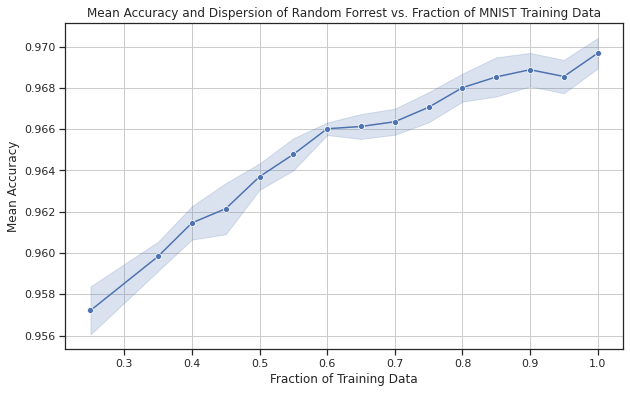

In [44]:
# Calculate mean and standard deviation for each fraction
mean_accuracies = [np.mean(frac_acc) for frac_acc in accuracies]
std_dev_accuracies = [np.std(frac_acc) for frac_acc in accuracies]

# Create a plot using Seaborn
plt.figure(figsize=(10, 6))
sns.lineplot(x=data_fracs, y=mean_accuracies, marker='o', color='b')
plt.fill_between(data_fracs, np.array(mean_accuracies) - np.array(std_dev_accuracies),
                 np.array(mean_accuracies) + np.array(std_dev_accuracies), alpha=0.2, color='b')
plt.title("Mean Accuracy and Dispersion of Random Forrest vs. Fraction of MNIST Training Data")
plt.xlabel("Fraction of Training Data")
plt.ylabel("Mean Accuracy")
plt.grid(True)
plt.show()

#### ReLU MLP on MNIST

##### Setup

In [26]:
def defaultMLPinit():
    return MLP(28 * 28, 256, 10, 3)

##### Results

In [27]:
def collect_results(root_path="experiments/mnist"):
    # Create an empty list to store the data from results.json files
    results = []

    # Walk through the folder and its subfolders
    for root, dirs, files in os.walk(root_path):
        for file in files:
            if file == "results.json":
                # Construct the full path to the results.json file
                results_json_path = os.path.join(root, file)
                
                # Load the JSON data from the results.json file
                with open(results_json_path, "r") as json_file:
                    result_data = json.load(json_file)
                    
                    # Append the data to the 'data' list
                    results.append(result_data)
    return results

In [28]:
# Convert data to a pandas DataFrame
def flatten_training_results(results):
    # Create a flat list to hold the flattened data
    flat_data = []

    # Flatten the nested lists within the 'test_accuracy' and 'train_accuracy' keys
    for item in results:
        lr = item["lr"]
        weight_decay = item["weight_decay"]
        scaling_factor = item["scaling_factor"]
        num_samples = item["num_samples"]
        optimization_steps = item["optimization_steps"]
        
        for (step, test_accuracy), (_,train_accuracy), (_, train_loss), (_,weight_norm) in zip(item["test_accuracy"], item["train_accuracy"], item["train_loss"], item["weight_norms"]):
        # for (step, test_accuracy), (_,train_accuracy) in zip(item["test_accuracy"], item["train_accuracy"]):
            flat_data.append({
                "lr": lr,
                "weight_decay": weight_decay,
                "scaling_factor": scaling_factor,
                "num_samples": num_samples,
                "optimization_steps": optimization_steps,
                "step": step,
                "test_accuracy": test_accuracy,
                "train_accuracy": train_accuracy,
                "train_loss": train_loss,
                "weight_norm": weight_norm
            })
    df = pd.DataFrame(flat_data)
    return df


In [127]:
def plot_flat_training_results(df):
    # Create a grid of subplots
    # g = sns.FacetGrid(df, col="num_samples", row="lr", margin_titles=True)
    g = sns.FacetGrid(df, col="num_samples", row="weight_decay", margin_titles=True)

    # Plot test_accuracy and train_accuracy data in each subplot
    g.map(sns.lineplot, "step", "test_accuracy", color="blue", label="Test Accuracy", markers=True, errorbar=None)
    g.map(sns.lineplot, "step", "train_accuracy", color="orange", label="Train Accuracy", markers=True, errorbar=None)
    # g.map(sns.lineplot, "step", "train_loss", color="purple", label="Train Loss", markers=True, errorbar=None)
    # g.map(sns.lineplot, "step", "weight_norm", color="red", label="Weight Norm", markers=True, errorbar=None)

    # # Set x-axis to log scale
    # g.set(xscale="log")

    # # Set titles and labels
    # g.set_axis_labels("Optimization Steps (log scale)", "Accuracy")
    g.set_titles(col_template="Num Samples = {col_name}", row_template="Weight Decay = {row_name}")

    # Add a legend
    g.add_legend()

    # # Create a second y-axis for the weighted_loss series
    # def plot_secondary_y(x, y, **kwargs):
    #     ax2 = plt.gca().twinx()
    #     ax2.plot(x, y, color="green", label="Train Loss")
    #     ax2.set_ylabel("Train Loss")
    #     ax2.figure.legend(loc="upper right")

    # g.map(plot_secondary_y, "step", "train_loss")
    # Show the plot
    plt.show()

In [30]:
len(full_mnist_train_dataset)

60000

In [51]:
# Define hyperparameters
lr= 0.001 # Learning Rate
weight_decay = 0.0001
eval_frequency = 10**1
scaling_factor= 8
total_steps = 10**4
batch_size = 200

num_samples = 1000

subset_indices = torch.randperm(len(full_mnist_train_dataset))[:num_samples]
train_dataset = Subset(full_mnist_train_dataset, subset_indices)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
train_eval_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)
test_loader = torch.utils.data.DataLoader(test_mnist_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

mnist_results_1000 = [train_loop(defaultMLPinit, device, total_steps, lr, weight_decay, scaling_factor, eval_frequency, train_loader, test_loader, train_eval_loader)]

[10000, 15000, 21000, 27000, 33000]


Acc: 100.0% | 82.5%: 100%|██████████| 10000/10000 [28:19<00:00,  5.88it/s]


In [39]:
results_path = path_join("experiments/mnist", 'mnist_results_1000.json')
if not 'mnist_results_1000' in locals() or mnist_results_1000 is not None:
    with open(results_path, 'r') as f:
                mnist_results_1000 = json.load(f)
else:
    with open(results_path, 'w') as f:
                json.dump(mnist_results_1000, f)
                

,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
0,0.001,0.0001,8,1000,10000,10,0.4499,0.488,46.481953,128.509271
1,0.001,0.0001,8,1000,10000,20,0.6395,0.702,15.311667,128.329144
2,0.001,0.0001,8,1000,10000,30,0.7369,0.818,7.791319,128.167691
3,0.001,0.0001,8,1000,10000,40,0.7526,0.859,5.255373,128.017318
4,0.001,0.0001,8,1000,10000,50,0.7718,0.922,1.939346,127.876928
...,...,...,...,...,...,...,...,...,...,...
995,0.001,0.0001,8,1000,10000,9960,0.8247,1.000,0.000034,59.299983
996,0.001,0.0001,8,1000,10000,9970,0.8243,1.000,0.000035,59.176878
997,0.001,0.0001,8,1000,10000,9980,0.8258,1.000,0.000029,59.053691
998,0.001,0.0001,8,1000,10000,9990,0.8252,1.000,0.000035,58.930426


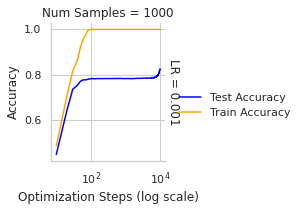

In [41]:
df = flatten_training_results(mnist_results_1000)
display(df)
plot_flat_training_results(df)

In [42]:
print(f" Test: {mnist_results_1000[0]['test_accuracy'][0]} -> {mnist_results_1000[0]['test_accuracy'][-1]}")
print(f" Train: {mnist_results_1000[0]['train_accuracy'][0]} -> {mnist_results_1000[0]['train_accuracy'][-1]}")

 Test: [10, 0.4499] -> [10000, 0.8252]
 Train: [10, 0.488] -> [10000, 1.0]


In [53]:
print(f" Test: {results[0]['test_accuracy'][0]} -> {results[0]['test_accuracy'][-1]}")
print(f" Train: {results[0]['train_accuracy'][0]} -> {results[0]['train_accuracy'][-1]}")

 Test: [10, 0.4499] -> [10000, 0.8252]
 Train: [10, 0.488] -> [10000, 1.0]


In [54]:
pd.DataFrame(results)

,lr,weight_decay,scaling_factor,num_samples,optimization_steps,test_accuracy,train_accuracy,train_loss,weight_norms
0,0.001,0.0001,8,1000,10000,"[[10, 0.4499], [20, 0.6395], [30, 0.7369], [40...","[[10, 0.488], [20, 0.702], [30, 0.818], [40, 0...","[(10, 46.48195266723633), (20, 15.311667442321...","[(10, 128.50927130950512), (20, 128.3291437695..."


In [134]:
# Define hyperparameters for the search
lr_values = [0.001, 0.01, 0.1]  # Learning rates
gamma_values = [0.0001, 0.001, 0.01]  # Weight decay values
data_fracs = [0.16667, 0.25, 0.35, 0.45, 0.55]
list_num_samples = [int(len(full_mnist_train_dataset) * i) for i in data_fracs]


# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**3
batch_size = 200

results = run_on_mnist(lambda: MLP(28 * 28, 256, 10, 3), list_num_samples, lr_values, gamma_values, scaling_factor, eval_frequency, batch_size, total_steps, "experiments/mnist")

List of sample sizes for each training setting: [10000, 15000, 21000, 27000, 33000]
Fraction: 10000
LR: 0.001
Weight Decay: 0.0001


Acc: 98.9% | 91.3%: 100%|██████████| 1000/1000 [00:52<00:00, 18.90it/s]


Fraction: 10000
LR: 0.001
Weight Decay: 0.001


Acc: 98.7% | 90.0%:  70%|██████▉   | 699/1000 [00:35<00:15, 19.53it/s]


KeyboardInterrupt: 

In [55]:
results_path = path_join("experiments/mnist", 'mnist_results.json')


In [130]:
results

[{'lr': 0.001,
  'weight_decay': 0.0001,
  'scaling_factor': 8,
  'num_samples': 10000,
  'optimization_steps': 1000,
  'test_accuracy': [[100, 0.8372],
   [200, 0.8739],
   [300, 0.8881],
   [400, 0.8943],
   [500, 0.8965],
   [600, 0.9006],
   [700, 0.9065],
   [800, 0.9058],
   [900, 0.9074],
   [1000, 0.9098]],
  'train_accuracy': [[100, 0.8642],
   [200, 0.92],
   [300, 0.9542],
   [400, 0.9654],
   [500, 0.9705],
   [600, 0.9723],
   [700, 0.9862],
   [800, 0.9899],
   [900, 0.9904],
   [1000, 0.9914]]}]

In [56]:
with open(results_path, 'w') as f:
            json.dump(results, f)

In [64]:
df = flatten_training_results(results)
df

,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
0,0.001,0.0001,8,1000,10000,10,0.4499,0.488,46.481953,128.509271
1,0.001,0.0001,8,1000,10000,20,0.6395,0.702,15.311667,128.329144
2,0.001,0.0001,8,1000,10000,30,0.7369,0.818,7.791319,128.167691
3,0.001,0.0001,8,1000,10000,40,0.7526,0.859,5.255373,128.017318
4,0.001,0.0001,8,1000,10000,50,0.7718,0.922,1.939346,127.876928
...,...,...,...,...,...,...,...,...,...,...
995,0.001,0.0001,8,1000,10000,9960,0.8247,1.000,0.000034,59.299983
996,0.001,0.0001,8,1000,10000,9970,0.8243,1.000,0.000035,59.176878
997,0.001,0.0001,8,1000,10000,9980,0.8258,1.000,0.000029,59.053691
998,0.001,0.0001,8,1000,10000,9990,0.8252,1.000,0.000035,58.930426


### Experiments Type I - Methodic removal of sub-categories
All the samples from a given category are at most distance 2 of each other plus a gaussian noise (std .02). A sample from one class is at least distance 4 of samples from any other class. This creates a perfectly separatable problem, although non trivial.

#### Benchmark: Decision Forrest

##### Auxiliary functions

In [31]:
sampled_train_df = train_df_doubleit.sample(frac=0.1, random_state=42)

- Create a balanced subsample of our test data to speed up the experiments results

In [35]:
test_df_doubleit10000 = balanced_df_sample(test_df_doubleit, 10000, 'class')
test_doubleit10000 = DoubleItDataset(test_df_doubleit10000)

Sample size per class size: 250


<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


##### First Sampling


In [45]:
# Define the data fractions
mnist_fracs = [0.25, 0.35, 0.4 , 0.45, 0.5 , 0.55,
             0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 ,
             0.95, 1.
             ]
mnist_ratio = 60000/(240000 *10) # len(full_mnist_train_dataset)/(len(train_df_doubleit) *10)
data_fracs = [ i*mnist_ratio for  i in mnist_fracs]
num_runs = 10
print(data_fracs)

[0.00625, 0.008749999999999999, 0.010000000000000002, 0.011250000000000001, 0.0125, 0.013750000000000002, 0.015, 0.01625, 0.017499999999999998, 0.018750000000000003, 0.020000000000000004, 0.02125, 0.022500000000000003, 0.02375, 0.025]


In [55]:
accuracies1 = calc_acc_rf_train_double_it(data_fracs, num_runs, train_df_doubleit, test_df_doubleit10000)

Double-it data fractions: 0.00625, 0.008749999999999999, 0.010000000000000002, 0.011250000000000001, 0.0125, 0.013750000000000002, 0.015, 0.01625, 0.017499999999999998, 0.018750000000000003, 0.020000000000000004, 0.02125, 0.022500000000000003, 0.02375, 0.025
Original train dataset size 240000
-------Fraction 0.0063----------
Shape of X_train: (1500, 117)
Shape of y_train: (1500,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:15<00:00,  1.56s/it]


Average acc: 0.9932199999999998
--------------------------------

-------Fraction 0.0087----------
Shape of X_train: (2100, 117)
Shape of y_train: (2100,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:21<00:00,  2.19s/it]


Average acc: 0.9943899999999999
--------------------------------

-------Fraction 0.0100----------
Shape of X_train: (2400, 117)
Shape of y_train: (2400,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


... (22 outputs left out)

100%|██████████| 10/10 [01:05<00:00,  6.50s/it]


Average acc: 0.99712
--------------------------------

-------Fraction 0.0250----------
Shape of X_train: (6000, 117)
Shape of y_train: (6000,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [01:09<00:00,  6.96s/it]

Average acc: 0.9970800000000001
--------------------------------



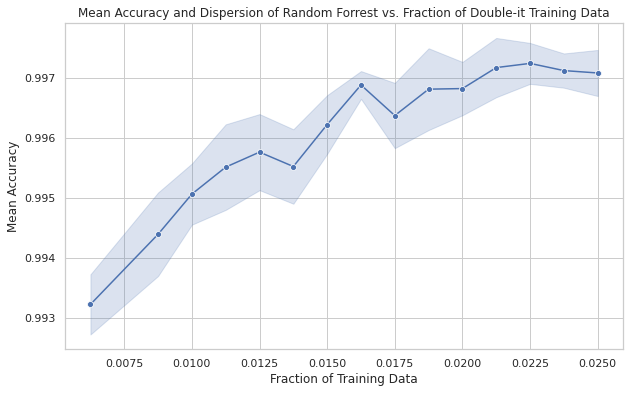

In [74]:
# plot dispersion of acc
plot_mean_acc(accuracies1, data_fracs)


##### Second Sampling


In [65]:
# Define the data fractions
mnist_fracs2 = [0.25, 0.35, 0.4 , 0.45, 0.5 , 0.55,
             0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 ,
             0.95, 1.
             ]
mnist_ratio2 = 60000/(240000 *50) # len(full_mnist_train_dataset)/(len(train_df_doubleit) *10)
data_fracs2 = [ i*mnist_ratio2 for  i in mnist_fracs2]
num_runs2 = 10
print(data_fracs2)

[0.00125, 0.0017499999999999998, 0.002, 0.0022500000000000003, 0.0025, 0.0027500000000000003, 0.003, 0.0032500000000000003, 0.0034999999999999996, 0.00375, 0.004, 0.00425, 0.0045000000000000005, 0.00475, 0.005]


In [66]:
accuracies2 = calc_acc_rf_train_double_it(data_fracs2, num_runs2, train_df_doubleit, test_df_doubleit10000)

Double-it data fractions: 0.00125, 0.0017499999999999998, 0.002, 0.0022500000000000003, 0.0025, 0.0027500000000000003, 0.003, 0.0032500000000000003, 0.0034999999999999996, 0.00375, 0.004, 0.00425, 0.0045000000000000005, 0.00475, 0.005
Original train dataset size 240000
-------Fraction 0.0013----------
Shape of X_train: (300, 117)
Shape of y_train: (300,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:04<00:00,  2.10it/s]


Average acc: 0.9423199999999999
--------------------------------

-------Fraction 0.0017----------
Shape of X_train: (420, 117)
Shape of y_train: (420,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:05<00:00,  1.78it/s]


Average acc: 0.97439
--------------------------------

-------Fraction 0.0020----------
Shape of X_train: (480, 117)
Shape of y_train: (480,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:06<00:00,  1.65it/s]


... (21 outputs left out)

100%|██████████| 10/10 [00:12<00:00,  1.21s/it]


Average acc: 0.99123
--------------------------------

-------Fraction 0.0050----------
Shape of X_train: (1200, 117)
Shape of y_train: (1200,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:12<00:00,  1.28s/it]

Average acc: 0.99171
--------------------------------



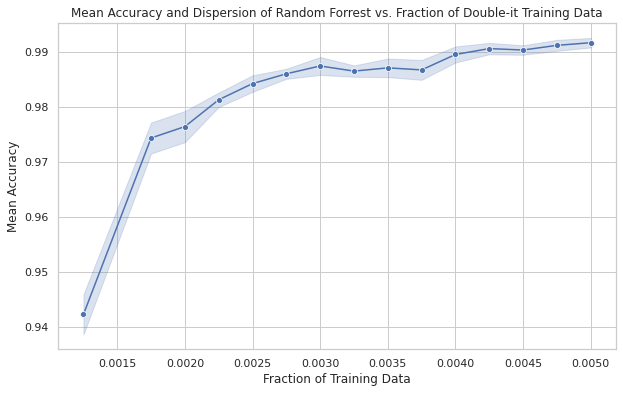

In [76]:
# plot dispersion of acc
plot_mean_acc(accuracies2, data_fracs2)

##### Third Sampling

In [88]:
# Define the data fractions
mnist_fracs3 = [0.25, 0.35, 0.4 , 0.45, 0.5 , 0.55,
             0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 ,
             0.95, 1.
             ]
mnist_ratio3 = 60000/(240000 *100) # len(full_mnist_train_dataset)/(len(train_df_doubleit) *10)
data_fracs3 = [ i*mnist_ratio3 for  i in mnist_fracs3]
data_counts3 = [int(np.round(i*len(train_df_doubleit))) for i in data_fracs3]
num_runs3 = 10
print(f"Data Fraction:{data_fracs3}")
print(f"Data counts: {data_counts3}")

Data Fraction:[0.000625, 0.0008749999999999999, 0.001, 0.0011250000000000001, 0.00125, 0.0013750000000000001, 0.0015, 0.0016250000000000001, 0.0017499999999999998, 0.001875, 0.002, 0.002125, 0.0022500000000000003, 0.002375, 0.0025]
Data counts: [150, 210, 240, 270, 300, 330, 360, 390, 420, 450, 480, 510, 540, 570, 600]


In [69]:
accuracies3 = calc_acc_rf_train_double_it(data_fracs3, num_runs3, train_df_doubleit, test_df_doubleit10000)

Double-it data fractions: 0.000625, 0.0008749999999999999, 0.001, 0.0011250000000000001, 0.00125, 0.0013750000000000001, 0.0015, 0.0016250000000000001, 0.0017499999999999998, 0.001875, 0.002, 0.002125, 0.0022500000000000003, 0.002375, 0.0025
Original train dataset size 240000
-------Fraction 0.0006----------
Shape of X_train: (150, 117)
Shape of y_train: (150,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:03<00:00,  2.76it/s]


Average acc: 0.72597
--------------------------------

-------Fraction 0.0009----------
Shape of X_train: (210, 117)
Shape of y_train: (210,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:03<00:00,  2.51it/s]


Average acc: 0.8767900000000001
--------------------------------

-------Fraction 0.0010----------
Shape of X_train: (240, 117)
Shape of y_train: (240,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


... (22 outputs left out)

100%|██████████| 10/10 [00:06<00:00,  1.50it/s]


Average acc: 0.9828699999999999
--------------------------------

-------Fraction 0.0025----------
Shape of X_train: (600, 117)
Shape of y_train: (600,)
Shape of X_test: (10000, 117)
Shape of y_test: (10000,)


100%|██████████| 10/10 [00:06<00:00,  1.43it/s]

Average acc: 0.98371
--------------------------------



In [ ]:
train_df_doubleit.describe()

,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,...,d109,d110,d111,d112,d113,d114,d115,d116,class,super_class
count,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,...,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000,240000.000000
mean,0.824802,-0.916740,-0.648409,-0.504217,-0.500888,-0.941210,0.059585,-0.787638,-0.194950,-0.077323,...,-1.167247,0.060083,-0.520092,0.452113,0.129430,0.421857,-0.317864,-0.693926,255.500000,255.500000
std,0.163418,0.201109,0.191295,0.145240,0.130878,0.144548,0.211668,0.172522,0.246381,0.210077,...,0.224464,0.197747,0.190016,0.154530,0.160516,0.169719,0.211881,0.225329,134.078801,124.089944
min,0.177189,-1.626799,-1.313391,-1.126787,-1.078183,-1.592935,-0.756744,-1.457946,-0.912184,-0.712700,...,-1.843386,-0.615326,-1.175290,-0.177159,-0.506296,-0.255276,-0.983567,-1.435224,31.000000,63.000000
25%,0.707439,-1.071128,-0.802330,-0.602345,-0.588832,-1.039265,-0.108908,-0.913542,-0.409890,-0.255661,...,-1.357443,-0.100137,-0.673633,0.338572,0.011965,0.300262,-0.494852,-0.880824,136.750000,195.750000
50%,0.824673,-0.916783,-0.648038,-0.504151,-0.500485,-0.941100,0.059246,-0.787761,-0.195622,-0.077088,...,-1.166747,0.059320,-0.520350,0.451964,0.129316,0.421828,-0.317772,-0.693462,253.500000,281.500000
75%,0.942049,-0.762375,-0.495140,-0.406314,-0.412310,-0.843136,0.227869,-0.661952,0.020259,0.101040,...,-0.977456,0.221010,-0.366372,0.565347,0.246939,0.542955,-0.141682,-0.507816,363.250000,341.250000
max,1.515021,-0.190036,0.023923,0.171375,0.079873,-0.274345,0.762089,-0.025255,0.623728,0.559083,...,-0.445263,0.707224,0.160150,1.078662,0.793516,1.140387,0.391745,0.062075,496.000000,396.000000


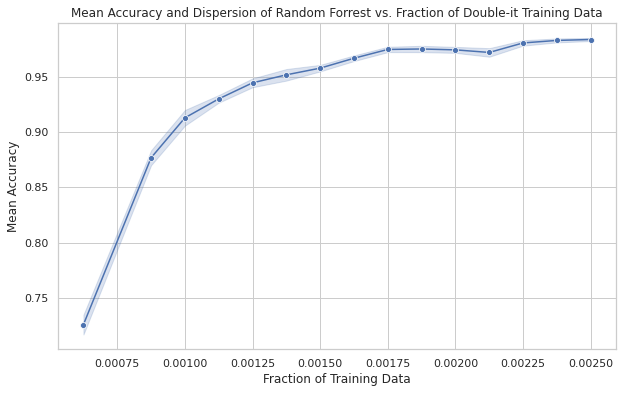

In [77]:
# plot dispersion of acc
plot_mean_acc(accuracies3, data_fracs3)

#### Different results on different datasets

##### Setup



In [36]:
data_fraq = list(np.linspace(0.00075, 0.00275, 5))
print( "DoubleIt data fractions: " + ", ".join([f"{i:7.5f}"for i in data_fraq]))
print( "DoubleIt sample sizes: " + ", ".join([str(int(len(train_df_doubleit)*i)) for i in data_fraq]))
print(f"DoubleIt total training samples: {len(train_df_doubleit)}")

DoubleIt data fractions: 0.00075, 0.00125, 0.00175, 0.00225, 0.00275
DoubleIt sample sizes: 180, 300, 420, 540, 660
DoubleIt total training samples: 240000


In [38]:
print(test_df_doubleit10000)
print(test_df_doubleit10000.dtypes)
#self.dataframe.loc[idx, self.feature_columns].values 
print(test_doubleit10000.dataframe)
print(test_doubleit10000.feature_columns)
print(torch.Tensor(test_doubleit10000.dataframe.loc[0, test_doubleit10000.feature_columns].values.astype('float32')))

            d0        d1        d2        d3        d4        d5        d6  \
0     0.846245 -0.992326 -0.807074 -0.321067 -0.355458 -1.149700  0.438783   
1     0.911020 -1.078648 -0.789116 -0.559736 -0.448148 -0.917343  0.286846   
2     1.000833 -1.080972 -0.738418 -0.475718 -0.596514 -1.021155  0.106869   
3     1.205112 -1.042292 -0.875730 -0.551142 -0.659673 -1.417795  0.146856   
4     0.877801 -1.125715 -0.739767 -0.391951 -0.574049 -1.073688  0.279700   
...        ...       ...       ...       ...       ...       ...       ...   
9995  0.521724 -0.688611 -0.648893 -0.734557 -0.559582 -0.675705 -0.054171   
9996  0.642531 -0.813604 -0.506277 -0.578796 -0.504131 -0.781650 -0.179814   
9997  0.716572 -0.734745 -0.479726 -0.527632 -0.265906 -0.826409  0.020405   
9998  0.622504 -0.696986 -0.440504 -0.462530 -0.434323 -0.920949 -0.402097   
9999  0.772505 -0.803047 -0.419133 -0.704970 -0.481600 -1.018651 -0.154179   

            d7        d8        d9  ...      d109      d110    

##### Balanced sampling
We evaluate the performance of our arquitectures at different training data set sizes. We highlight that the most common dataset sizes were grokking have been reported are 1000 samples. Our data dimensionality is compatible with the MNIST, one of such datasets used.


In [39]:
train_df_doubleit10000 = balanced_df_sample(train_df_doubleit, 10000, 'class')
train_doubleit10000 = DoubleItDataset(train_df_doubleit10000)

Sample size per class size: 250


<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


In [41]:
# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
weight_decay_values = [0.0001]  # Weight decay values
list_num_samples = [150, 210, 240, 270, 300]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**3
batch_size = 200


def balanced_double_it_class_sampler(dataset, num_samples):
    sampled_df = balanced_df_sample(dataset.dataframe, num_samples, 'class')
    return DoubleItDataset(sampled_df)
        

results_mlp_balanced = run_on_dataset(model_init=lambda: MLP(117, 256, 4, 3),
                         list_num_samples=list_num_samples,
                         sample_method= balanced_double_it_class_sampler,
                         lr_values=lr_values,
                         weight_decay_values=weight_decay_values,
                         scaling_factor=scaling_factor,
                         eval_frequency=eval_frequency,
                         batch_size=batch_size,
                         total_steps=total_steps, train_dataset=train_doubleit10000,
                         test_dataset=test_doubleit10000,
                         results_folder="experiments/doubleit_10000_mlp")

<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


List of sample sizes for each training setting: [150, 210, 240, 270, 300]
Sample size per class size: 3
Fraction: 150
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 99.0%: 100%|██████████| 1000/1000 [01:39<00:00, 10.01it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 5
Fraction: 210
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.3%: 100%|██████████| 1000/1000 [02:15<00:00,  7.40it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 6
Fraction: 240
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.8%: 100%|██████████| 1000/1000 [01:40<00:00,  9.94it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 6
Fraction: 270
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.9%: 100%|██████████| 1000/1000 [01:40<00:00,  9.92it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 7
Fraction: 300
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.7%: 100%|██████████| 1000/1000 [01:49<00:00,  9.17it/s]


,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
0,0.001,0.0001,8,120,1000,100,0.9879,1.0,4.392698e-06,118.894275
1,0.001,0.0001,8,120,1000,200,0.9879,1.0,1.836614e-06,112.594548
2,0.001,0.0001,8,120,1000,300,0.9881,1.0,1.249617e-06,108.736076
3,0.001,0.0001,8,120,1000,400,0.9883,1.0,8.830954e-07,106.415014
4,0.001,0.0001,8,120,1000,500,0.9886,1.0,7.172117e-07,105.010663
5,0.001,0.0001,8,120,1000,600,0.9889,1.0,5.741716e-07,104.122998
6,0.001,0.0001,8,120,1000,700,0.9895,1.0,5.274844e-07,103.511567
7,0.001,0.0001,8,120,1000,800,0.9897,1.0,5.016573e-07,103.041159
8,0.001,0.0001,8,120,1000,900,0.9899,1.0,4.768235e-07,102.640043
9,0.001,0.0001,8,120,1000,1000,0.9899,1.0,4.440428e-07,102.271859


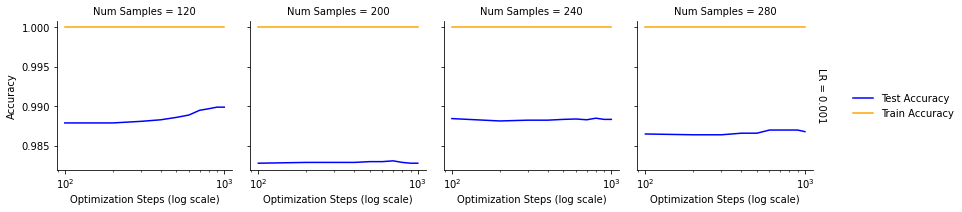

In [45]:
df = flatten_training_results(results_mlp_balanced)
display(df)
plot_flat_training_results(df)

Table with results of X epochs across datasets
Table with results by iterations

Predictably, the accuracy of our classifiers increases as we increases the training sample size, even if we keep computation fixed (i.e. how many data ).


##### Unbalanced sampling
We now evaluate the performance of the classfers when we drop 100% of half subclasses that compose a class. This forces an extreme data shift from the test distribution and we expect an performance drop that is not recuperable from grokking (i.e. from training during a longer period of time).


In [46]:

# Sample 50% of the classes in each super-class
underrepresented_classes= sample_classes(doubleit_class_map, .5, random_seed=42) 
print(f"There are {len(underrepresented_classes)} classes to be downsampled. They are: {underrepresented_classes}")
train_df_doubleit10000_frac_0 = unbalanced_df_sample(train_df_doubleit, 10000, 'class', underrepresented_classes = underrepresented_classes, fraction = 0.0)
train_doubleit10000_frac_0 = DoubleItDataset(train_df_doubleit10000_frac_0)

There are 20 classes to be downsampled. They are: [47, 31, 61, 319, 63, 208, 176, 248, 240, 224, 67, 451, 259, 339, 331, 428, 140, 392, 397, 398]
Sample size per class size: 500.0
Empty class 61
Empty class 259
Empty class 208
Empty class 248
Empty class 63
Empty class 451
Empty class 398
Empty class 397
Empty class 176


<ipython-input-33-2ad4d6e90812>:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  unbalanced_df = pd.concat([unbalanced_df, class_samples], axis=0)


Empty class 224
Empty class 331
Empty class 140
Empty class 319
Empty class 240
Empty class 428
Empty class 31
Empty class 67
Empty class 339
Empty class 47
Empty class 392


In [81]:
def unbalanced_double_it_class_sampler_factory(underrepresented_classes, fraction, target='class', random_state=42):
    def un(dataset, num_samples):
        sampled_df = unbalanced_df_sample(dataset = dataset.dataframe,
                                          num_samples = num_samples,
                                          target = target,
                                          underrepresented_classes = underrepresented_classes,
                                          fraction = fraction,
                                          random_state = random_state)
        return DoubleItDataset(sampled_df)
    return un

In [48]:
train_df_doubleit10000_frac_0['class'].describe()

count     10000
unique       20
top         321
freq        500
Name: class, dtype: int64

In [57]:
train_df_doubleit10000_frac_0.loc[0, :]

d0             0.972629
d1            -1.064238
d2            -0.790064
d3            -0.363369
d4            -0.802887
                 ...   
d114           0.469268
d115          -0.500296
d116          -0.549581
class               321
super_class         323
Name: 0, Length: 119, dtype: object

In [51]:
# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
weight_decay_values = [0.0001]  # Weight decay values
list_num_samples = [150, 210, 240, 270, 300]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**3
batch_size = 200

results_mlp_unbalanced = run_on_dataset(model_init=lambda: MLP(117, 256, 4, 3),
                         list_num_samples=list_num_samples,
                         sample_method= balanced_double_it_class_sampler,
                         lr_values=lr_values,
                         weight_decay_values=weight_decay_values,
                         scaling_factor=scaling_factor,
                         eval_frequency=eval_frequency,
                         batch_size=batch_size,
                         total_steps=total_steps,
                         train_dataset=train_doubleit10000_frac_0, # Removed 50% of classes
                         test_dataset=test_doubleit10000,
                         results_folder="experiments/doubleit_10000_classes_0.5_frac_0_mlp")

<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


List of sample sizes for each training setting: [150, 210, 240, 270, 300]
Sample size per class size: 7
Fraction: 150
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 95.3%: 100%|██████████| 1000/1000 [01:47<00:00,  9.34it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 10
Fraction: 210
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 95.7%: 100%|██████████| 1000/1000 [02:12<00:00,  7.54it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 12
Fraction: 240
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.6%: 100%|██████████| 1000/1000 [01:39<00:00, 10.09it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 13
Fraction: 270
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 94.0%: 100%|██████████| 1000/1000 [01:43<00:00,  9.67it/s]
<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 15
Fraction: 300
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 97.2%: 100%|██████████| 1000/1000 [01:52<00:00,  8.89it/s]


,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
0,0.001,0.0001,8,140,1000,100,0.9533,1.0,7.075732e-07,117.912528
1,0.001,0.0001,8,140,1000,200,0.9533,1.0,5.228077e-07,110.886555
2,0.001,0.0001,8,140,1000,300,0.9534,1.0,3.865733e-07,106.516628
3,0.001,0.0001,8,140,1000,400,0.9532,1.0,2.843965e-07,103.836198
4,0.001,0.0001,8,140,1000,500,0.9530,1.0,2.060604e-07,102.171554
5,0.001,0.0001,8,140,1000,600,0.9528,1.0,2.035059e-07,101.084148
6,0.001,0.0001,8,140,1000,700,0.9529,1.0,2.000998e-07,100.308543
7,0.001,0.0001,8,140,1000,800,0.9525,1.0,2.086147e-07,99.694563
8,0.001,0.0001,8,140,1000,900,0.9524,1.0,2.103176e-07,99.161997
9,0.001,0.0001,8,140,1000,1000,0.9526,1.0,2.060602e-07,98.669835


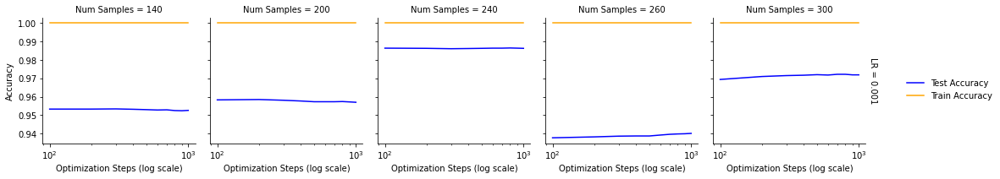

In [52]:
df_mlp_unbalanced = flatten_training_results(results_mlp_unbalanced)
display(df_mlp_unbalanced)
plot_flat_training_results(df_mlp_unbalanced)

In [ ]:
# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
gamma_values = [0.0001]  # Weight decay values
#data_fracs = [0.16667, 0.25, 0.35, 0.45, 0.55]
#list_num_samples = [int(len(full_mnist_train_dataset) * i) for i in data_fracs]
list_num_samples = [100, 200, 500, 700]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**4
batch_size = 200

results = run_on_dataset(lambda: MLP(117, 256, 4, 3), list_num_samples, lr_values, gamma_values, scaling_factor, eval_frequency, batch_size, total_steps, train_doubleit10000_frac_0, train_doubleit10000_frac_0, "experiments/doubleit_classes_0.5_frac_0_mlp")

Then we soften our data unbalance by keeping 10%, 20%, and 30% of our dropped classes. This configuration creates the possibility for grokking.

Figure: accuracy by drop fraction, dataset size
Figure: accuracy by drop fraction, iteration count

Which configurations had grokking? Can we explain it as a distribution shift? Can we visualize the grokking "fading as we increase data sample size"? Can we visualize the grokking "fading as we decrease distribution shift"?

### Experiments Type II - Equidistant Mega-class

This class of experiments we create "mega-classes" from the classes. We then perform the drops on other classes. The main difference here from the experiments in section "Experiments Type I" is that the mega-classes do not have the same distance restrictions that classes had before. Thus when we drop a class it is more cunfusing to the model.


##### Setup

In [53]:
num_mega_classes = 2

classes = np.asarray(df_doubleit["super_class"].unique())
mega_class_size = len(classes)//num_mega_classes
np_r = np.random.RandomState(42)
np_r.shuffle(classes)
mega_classes_map = { i: classes[i*mega_class_size:(i+1)*mega_class_size].tolist() for i in range(num_mega_classes)}
mega_classes_map

{0: [240, 396], 1: [63, 323]}

In [54]:
inverse_mega_classes_map =  { i: mc for mc,c in mega_classes_map.items() for i in c}

df_doubleit["mega_class"] = df_doubleit["super_class"].map(inverse_mega_classes_map)
train_df_doubleit["mega_class"] = train_df_doubleit["super_class"].map(inverse_mega_classes_map)
test_df_doubleit["mega_class"] = test_df_doubleit["super_class"].map(inverse_mega_classes_map)


In [78]:
underrepresented_super_classes= sample_classes(mega_classes_map, .5, random_seed=42)
print(f"There are {len(underrepresented_super_classes)} classes to be downsampled. They are: {underrepresented_super_classes}")

There are 2 classes to be downsampled. They are: [240, 63]


In [56]:
train_mega_df_doubleit1000 = balanced_df_sample(train_df_doubleit, 1000, 'super_class')
train_mega_doubleit1000 = DoubleItDataset(train_mega_df_doubleit1000)

Sample size per class size: 250


<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


In [57]:
train_mega_df_doubleit1000_frac_0 = unbalanced_df_sample(train_df_doubleit, 1000, 'super_class', underrepresented_classes = underrepresented_super_classes, fraction = 0.0)
train_mega_doubleit1000_frac_0 = DoubleItDataset(train_mega_df_doubleit1000_frac_0)

Sample size per class size: 500.0
Empty class 63
Empty class 240


<ipython-input-33-2ad4d6e90812>:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  unbalanced_df = pd.concat([unbalanced_df, class_samples], axis=0)


In [67]:
test_mega__df_doubleit10000 = balanced_df_sample(test_df_doubleit, 1000, 'super_class')
test_mega_doubleit10000 = DoubleItDataset(test_mega__df_doubleit10000)

Sample size per class size: 250


<ipython-input-33-2ad4d6e90812>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


In [69]:
print(train_mega_doubleit1000[0])
print(test_mega_doubleit10000[0])

(tensor([ 0.9570, -0.9936, -0.6686, -0.5422, -0.5961, -1.0753,  0.2086, -0.4711,
         0.0249,  0.0581,  0.6832, -1.5340, -0.7716, -0.3739,  0.5965,  0.4446,
         0.1303,  0.5562, -0.3899,  1.0509,  0.2633,  0.2546,  0.7094,  0.0207,
         0.1379,  0.7195,  0.3889,  0.6272,  0.4438,  0.4405, -0.9478, -0.0903,
         0.7500, -0.1317, -0.4137,  0.8961,  0.3641,  0.4492,  0.4385, -0.0792,
        -0.1097,  0.8141,  0.5356,  0.9481,  0.6132,  0.0838,  0.8190,  0.5262,
        -0.0044, -0.3448,  0.5479, -0.7259,  0.1595,  0.0805, -0.2675, -0.8508,
         0.4603,  0.3736, -0.0551,  0.8809,  0.4372, -0.3742, -0.2553, -0.8858,
         0.8224, -0.1306, -0.3692, -0.9844,  0.2442,  0.5002, -0.6949,  0.3430,
        -0.7603,  0.7419,  0.3419,  0.4566, -0.7166, -0.3840, -0.2292, -0.1573,
         0.1289, -0.0821,  0.0304,  0.3280,  1.0068, -0.5459, -0.2886, -0.0576,
         0.1526,  0.4653,  1.1115,  0.1088,  0.4005, -0.9097, -0.8316, -0.5009,
        -0.1630,  0.0221,  0.3902, -0.5

In [119]:
# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
weight_decay_values = [0.0001]  # Weight decay values
list_num_samples = [150, 210, 240, 270, 300, 1000]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**3
batch_size = 200

results_mlp_mega_class_balanced = run_on_dataset(model_init=lambda: MLP(117, 256, 4, 3),
                         list_num_samples=list_num_samples,
                         sample_method= balanced_double_it_super_class_sampler,
                         lr_values=lr_values,
                         weight_decay_values=weight_decay_values,
                         scaling_factor=scaling_factor,
                         eval_frequency=eval_frequency,
                         batch_size=batch_size,
                         total_steps=total_steps,
                         train_dataset=train_mega_doubleit1000,
                         test_dataset=test_mega_doubleit10000,
                         results_folder="experiments/doubleit_mega_1000_mlp")

<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


List of sample sizes for each training setting: [150, 210, 240, 270, 300, 1000]
Sample size per class size: 250
Fraction: 1000
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.8%: 100%|██████████| 1000/1000 [01:33<00:00, 10.68it/s]
<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 75
Fraction: 300
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.1%: 100%|██████████| 1000/1000 [01:09<00:00, 14.34it/s]
<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 67
Fraction: 270
LR: 0.001
Weight Decay: 0.0001


... (3 outputs left out)

Sample size per class size: 52
Fraction: 210
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 98.0%: 100%|██████████| 1000/1000 [00:49<00:00, 20.16it/s]
<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 37
Fraction: 150
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 95.3%: 100%|██████████| 1000/1000 [01:07<00:00, 14.74it/s]


,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
0,0.001,0.0001,8,1000,1000,100,0.986,1.0,1.470247e-06,119.553842
1,0.001,0.0001,8,1000,1000,200,0.987,1.0,1.045392e-06,113.645844
2,0.001,0.0001,8,1000,1000,300,0.987,1.0,2.510058e-06,109.907752
3,0.001,0.0001,8,1000,1000,400,0.987,1.0,3.187327e-06,107.538674
4,0.001,0.0001,8,1000,1000,500,0.988,1.0,3.754975e-07,105.989607
5,0.001,0.0001,8,1000,1000,600,0.988,1.0,1.251684e-07,104.907730
6,0.001,0.0001,8,1000,1000,700,0.988,1.0,3.022593e-06,104.081183
7,0.001,0.0001,8,1000,1000,800,0.988,1.0,2.044403e-07,103.390662
8,0.001,0.0001,8,1000,1000,900,0.988,1.0,2.366017e-06,102.772589
9,0.001,0.0001,8,1000,1000,1000,0.988,1.0,4.082752e-07,102.194357


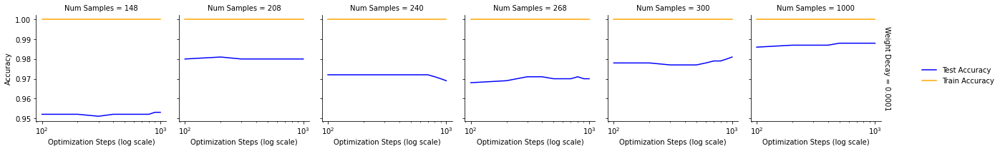

In [120]:
df_mlp_mega_class_balanced = flatten_training_results(results_mlp_mega_class_balanced)
display(df_mlp_mega_class_balanced)
plot_flat_training_results(df_mlp_mega_class_balanced)

In [124]:

# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
weight_decay_values = [0.0001]  # Weight decay values
list_num_samples = [150, 210, 240, 270, 300, 1000]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**3
batch_size = 200


results_mlp_mega_class_unbalanced = run_on_dataset(model_init=lambda: MLP(117, 256, 4, 3),
                         list_num_samples=list_num_samples,
                         sample_method= balanced_double_it_class_sampler,
                         lr_values=lr_values,
                         weight_decay_values=weight_decay_values,
                         scaling_factor=scaling_factor,
                         eval_frequency=eval_frequency,
                         batch_size=batch_size,
                         total_steps=total_steps,
                         train_dataset=train_mega_doubleit1000_frac_0,
                         test_dataset=test_mega_doubleit10000,
                         results_folder="experiments/doubleit_mega_1000_classes_0.5_frac_0_mlp")

List of sample sizes for each training setting: [150, 210, 240, 270, 300, 1000]
Fraction: 1000
LR: 0.001
Weight Decay: 0.0001


  0%|          | 0/1000 [00:00<?, ?it/s]

Acc: 100.0% | 81.1%: 100%|██████████| 1000/1000 [01:35<00:00, 10.48it/s]
<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 15
Fraction: 300
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 78.6%: 100%|██████████| 1000/1000 [01:10<00:00, 14.10it/s]
<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 13
Fraction: 270
LR: 0.001
Weight Decay: 0.0001


... (3 outputs left out)

Sample size per class size: 10
Fraction: 210
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 72.1%: 100%|██████████| 1000/1000 [01:30<00:00, 11.02it/s]
<ipython-input-90-379e543b3b59>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  balanced_df = pd.concat([balanced_df, class_samples], axis=0)


Sample size per class size: 7
Fraction: 150
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 69.2%: 100%|██████████| 1000/1000 [01:05<00:00, 15.33it/s]


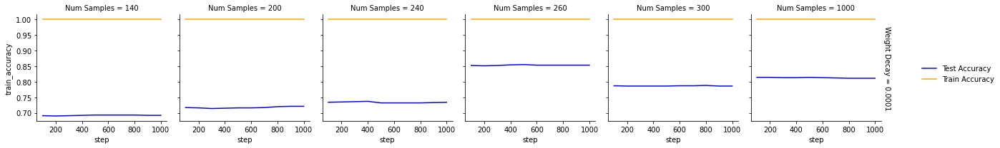

In [128]:
df_mlp_mega_class_unbalanced = flatten_training_results(results_mlp_mega_class_unbalanced)
# display(df_mlp_mega_class_unbalanced)
plot_flat_training_results(df_mlp_mega_class_unbalanced)

In [83]:
underrepresented_super_classes

[240, 63]

In [132]:
# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
weight_decay_values = [0.01]  # Weight decay values
# list_num_samples = [150, 210, 240, 270, 300, 1000]
list_num_samples = [210, 256, 512]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**4
batch_size = 200


unbalance_10_percent = unbalanced_double_it_class_sampler_factory(underrepresented_super_classes, 0.1, target='super_class', random_state=42)


results_mlp_mega_class_10_percent = run_on_dataset(model_init=lambda: MLP(117, 256, 4, 3),
                         list_num_samples=list_num_samples,
                         sample_method= unbalance_10_percent,
                         lr_values=lr_values,
                         weight_decay_values=weight_decay_values,
                         scaling_factor=scaling_factor,
                         eval_frequency=eval_frequency,
                         batch_size=batch_size,
                         total_steps=total_steps,
                         train_dataset=train_mega_doubleit1000,
                         test_dataset=test_mega_doubleit10000,
                         results_folder="experiments/doubleit_mega_1000_classes_0.5_frac_0.10_mlp")

<ipython-input-90-379e543b3b59>:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  unbalanced_df = pd.concat([unbalanced_df, class_samples], axis=0)


List of sample sizes for each training setting: [210, 256, 512]
Sample size per class: 232.72727272727272/4 [2.2]
Fraction: 512
LR: 0.001
Weight Decay: 0.01


Acc: 100.0% | 96.2%:  87%|████████▋ | 8662/10000 [11:30<01:37, 13.67it/s]

: 

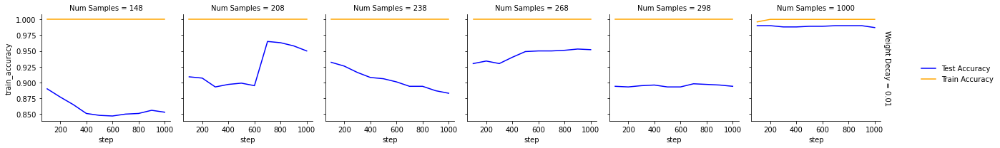

In [131]:
df_mlp_mega_class_10_percent = flatten_training_results(results_mlp_mega_class_10_percent)
#display(df_mlp_mega_class_10_percent)
plot_flat_training_results(df_mlp_mega_class_10_percent)

In [117]:
# Define hyperparameters for the search
lr_values = [0.001]  # Learning rates
weight_decay_values = [0.0001, 0.001, 0.01]  # Weight decay values
list_num_samples = [150, 210, 240, 270, 300]

# Define hyperparameters from literature
print(f"List of sample sizes for each training setting: {list_num_samples}")
eval_frequency = 100
scaling_factor= 8
total_steps = 10**3 *2
batch_size = 200


unbalance_1_percent = unbalanced_double_it_class_sampler_factory(underrepresented_super_classes, 0.01, target='super_class', random_state=42)


results_mlp_mega_class_1_percent = run_on_dataset(model_init=lambda: MLP(117, 256, 4, 3),
                         list_num_samples=list_num_samples,
                         sample_method= unbalance_1_percent,
                         lr_values=lr_values,
                         weight_decay_values=weight_decay_values,
                         scaling_factor=scaling_factor,
                         eval_frequency=eval_frequency,
                         batch_size=batch_size,
                         total_steps=total_steps,
                         train_dataset=train_mega_doubleit1000,
                         test_dataset=test_mega_doubleit10000,
                         cumulative_train_samples=True,
                         results_folder="experiments/doubleit_mega_1000_classes_0.5_frac_0.01_mlp")

<ipython-input-90-379e543b3b59>:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  unbalanced_df = pd.concat([unbalanced_df, class_samples], axis=0)


List of sample sizes for each training setting: [150, 210, 240, 270, 300]
Sample size per class: 148.5148514851485/4 [2.02]
Fraction: 300
LR: 0.001
Weight Decay: 0.0001


Acc: 100.0% | 81.5%: 100%|██████████| 2000/2000 [02:19<00:00, 14.34it/s]


Fraction: 300
LR: 0.001
Weight Decay: 0.001


Acc: 100.0% | 86.3%: 100%|██████████| 2000/2000 [02:19<00:00, 14.38it/s]


Fraction: 300
LR: 0.001
Weight Decay: 0.01


... (21 outputs left out)

Fraction: 150
LR: 0.001
Weight Decay: 0.001


Acc: 100.0% | 73.7%: 100%|██████████| 2000/2000 [02:16<00:00, 14.70it/s]


Fraction: 150
LR: 0.001
Weight Decay: 0.01


Acc: 100.0% | 70.3%: 100%|██████████| 2000/2000 [02:16<00:00, 14.66it/s]


,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
0,0.001,0.0001,8,298,2000,100,0.812,1.0,0.000000,119.271368
1,0.001,0.0001,8,298,2000,200,0.812,1.0,0.000000,113.172474
2,0.001,0.0001,8,298,2000,300,0.815,1.0,0.000000,109.335046
3,0.001,0.0001,8,298,2000,400,0.815,1.0,0.000000,106.932349
4,0.001,0.0001,8,298,2000,500,0.814,1.0,0.000000,105.394780
...,...,...,...,...,...,...,...,...,...,...
295,0.001,0.0100,8,148,2000,1600,0.716,1.0,0.000096,48.787113
296,0.001,0.0100,8,148,2000,1700,0.710,1.0,0.000118,46.915121
297,0.001,0.0100,8,148,2000,1800,0.705,1.0,0.000135,45.112640
298,0.001,0.0100,8,148,2000,1900,0.704,1.0,0.000152,43.374406


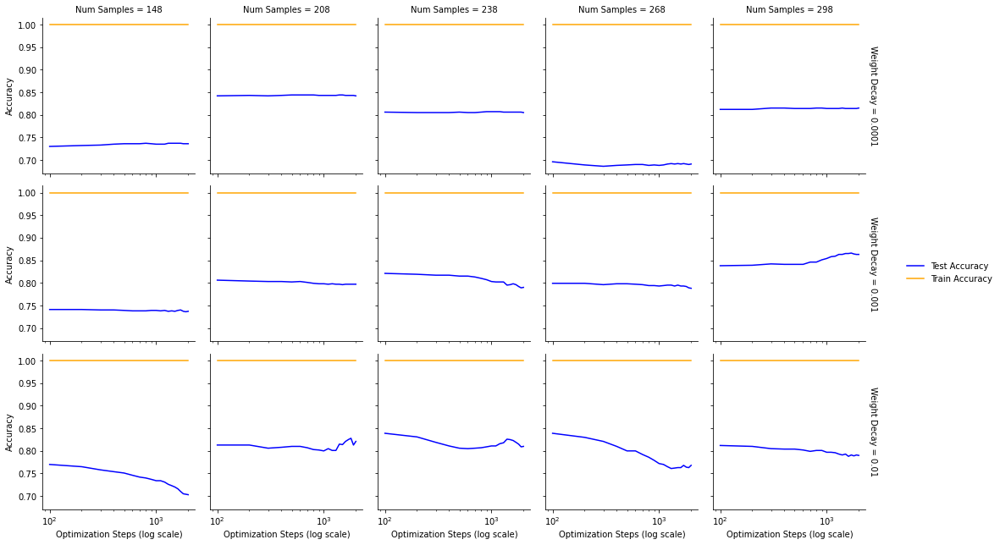

In [118]:
df_mlp_mega_class_1_percent = flatten_training_results(results_mlp_mega_class_1_percent)
display(df_mlp_mega_class_1_percent)
plot_flat_training_results(df_mlp_mega_class_1_percent)

In [101]:
df_mlp_mega_class_1_percent[df_mlp_mega_class_1_percent['weight_decay'] == 0.01]

,lr,weight_decay,scaling_factor,num_samples,optimization_steps,step,test_accuracy,train_accuracy,train_loss,weight_norm
20,0.001,0.01,8,148,1000,100,0.787,1.0,0.000000e+00,113.069911
21,0.001,0.01,8,148,1000,200,0.790,1.0,0.000000e+00,100.658283
22,0.001,0.01,8,148,1000,300,0.793,1.0,0.000000e+00,91.241117
23,0.001,0.01,8,148,1000,400,0.795,1.0,7.249212e-09,84.099925
24,0.001,0.01,8,148,1000,500,0.803,1.0,1.948975e-06,78.580314
25,0.001,0.01,8,148,1000,600,0.810,1.0,9.823651e-06,74.164052
26,0.001,0.01,8,148,1000,700,0.819,1.0,9.036952e-06,70.479804
27,0.001,0.01,8,148,1000,800,0.816,1.0,8.168952e-06,67.281606
28,0.001,0.01,8,148,1000,900,0.828,1.0,6.686105e-06,64.415002
29,0.001,0.01,8,148,1000,1000,0.834,1.0,6.437280e-06,61.785443



Table with results of X epochs across datasets
Table with results by iterations

Predictably, the accuracy of our classifiers increases as we increases the training sample size, even if we keep computation fixed (i.e. how many data points considered). The accuracy is not comparable from the other class of experiments since now its a balanced binary classification (thus, a random guess classifier would have acc 50%).

We now evaluate the performance of the classfers when we drop 100% of half subclasses that compose a class. This forces an extreme data shift from the test distribution and we expect an performance drop that is not recuperable from grokking (i.e. from training during a longer period of time).

Then we soften our data unbalance by keeping 25%, 35%, 45%, and 55% of our dropped classes. This configuration creates the possibility for grokking.

Figure: accuracy by drop fraction, dataset size
Figure: accuracy by drop fraction, iteration count


## Final Remarks

- summary of the findings
- Next steps:
    - TransformerLens to inspect the models at different stages of the training curve specially around grokking